# MVSGaussian → SplatFormer: OOD Novel View Synthesis Pipeline

## CONFIG

In [ ]:

OOD_DATASET = "shapenetOOD"
OOD_SH_DEGREE = 0
OOD_TESTSET_ROOT = "/content/data/ood-nvs/test-set"
OOD_TESTSET_GDRIVE_ID = "1-mUCl-yxe1aE0rrQDHKlXk1J2n8d1-60"
COLMAP_ROOT_OOD = os.path.join(OOD_TESTSET_ROOT, OOD_DATASET, "colmap")

N_SCENES_OOD = 10
CKPT_PATH = "/content/drive/MyDrive/checkpoints/train-on-shapenet.pth"
PLY_OUTPUT_DIR = "/content/mvs_output_ood"


## Step 1 - Experiment Configurtion

To set up the compatible environment, download the env package and run the following cells

In [ ]:
import os, subprocess, time
print("=== 1e. Import environment from drive ===")

from google.colab import drive

# 1. Mount Google Drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive", force_remount=True)

ENV_BACKUP_TAR = "/content/drive/MyDrive/splatformer_full_env_backup.tar"

# 2. Drive double check
if not os.path.isfile(ENV_BACKUP_TAR):
    candidates = subprocess.run(
        ["find", "/content/drive/MyDrive", "-name", "splatformer_full_env_backup.tar"],
        capture_output=True, text=True
    ).stdout.splitlines()
    if candidates:
        ENV_BACKUP_TAR = candidates[0]


# 3. Unzip the environment
if os.path.isfile(ENV_BACKUP_TAR):
    res = subprocess.run(["tar", "-xf", ENV_BACKUP_TAR, "-C", "/"], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if res.returncode == 0:
        ok_conda = os.path.isfile("/usr/local/miniconda/bin/conda")
        ok_python = os.path.isfile("/usr/local/miniconda/envs/splatformer/bin/python")
        ok_nvcc = os.path.isfile("/usr/local/cuda-11.8/bin/nvcc")
        if ok_conda and ok_python and ok_nvcc:
            print("✅ Đã khôi phục thành công env 'splatformer' + CUDA toolkit!")
        else:
            print(f"⚠️ Giải nén hoàn tất nhưng thiếu file hệ thống (conda={ok_conda}, python={ok_python}, nvcc={ok_nvcc}).")
    else:
        print(f"⚠️ Lỗi khi giải nén:\n{res.stdout[-2000:]}")
else:
    print(f"❌ Không tìm thấy file {ENV_BACKUP_TAR} trên Google Drive của bạn.")

print("✅ Finish 1e")

=== BƯỚС 1e: Khôi phục nhanh env 'splatformer' từ Drive ===
Mounted at /content/drive
-> Tìm thấy file backup tại đường dẫn phụ: /content/drive/MyDrive/Study/3DGS/splatformer_full_env_backup.tar
-> Tìm thấy file backup tại /content/drive/MyDrive/Study/3DGS/splatformer_full_env_backup.tar, đang giải nén (mất khoảng 1-3 phút)...
✅ Đã khôi phục thành công env 'splatformer' + CUDA toolkit!
✅ Xong BƯỚС 1e


## Step 2 - Clone repos and install library

In [ ]:
import os, gdown

ckpt_dir = "/content/drive/MyDrive/checkpoints"
os.makedirs(ckpt_dir, exist_ok=True)
target_ckpt = os.path.join(ckpt_dir, "train-on-shapenet.pth")

if not os.path.exists(target_ckpt):
    print("-> Đang tải train-on-shapenet.pth vào Google Drive...")
    gdown.download(id="1rLsQdwzCryZgd9bE3hydvZ8F3pPSXLRu", output=target_ckpt, quiet=False)
    print("Finish downloading ShapeNet!")
else:
    print(f"check point is available")

✅ Checkpoint đã có sẵn tại /content/drive/MyDrive/checkpoints/train-on-shapenet.pth


In [ ]:
import shutil

PIP_BIN = "/usr/local/miniconda/envs/splatformer/bin/pip"


def clone_fresh(url, dest):
    """Chỉ clone nếu thư mục chưa tồn tại; nếu đã có thì giữ nguyên để bảo toàn các patch code."""
    if os.path.exists(dest) and os.listdir(dest):
        print(f"-> Thư mục {dest} đã có sẵn, bỏ qua clone.")
        return

    # Nếu thư mục chưa có hoặc rỗng thì mới clone
    if os.path.exists(dest):
        subprocess.run(["rm", "-rf", dest], check=True)

    print(f"-> Clone {url} -> {dest}")
    r = subprocess.run(["git", "clone", url, dest], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Clone {url} failed:\n{r.stderr}")


os.chdir("/content")

clone_fresh("https://github.com/TQTQliu/MVSGaussian.git", "/content/MVSGaussian")
clone_fresh("https://github.com/ChenYutongTHU/SplatFormer.git", "/content/SplatFormer")

backup_dir = "/content/drive/MyDrive/MVSGaussian_backup"
if os.path.exists(backup_dir):
    print(f"-> Khôi phục backup từ {backup_dir}...")
    try:
        shutil.copytree(backup_dir, "/content/MVSGaussian", dirs_exist_ok=True)
        print(" Đã khôi phục backup.")
    except Exception as e:
        print(f"⚠️ Khôi phục backup thất bại (bỏ qua, dùng bản clone gốc): {e}")
else:
    print(f"-> Không có backup tại {backup_dir}, bỏ qua (dùng bản clone gốc).")

subprocess.run(["git", "config", "--global", "url.https://github.com/.insteadOf", "git@github.com:"],
                cwd="/content/SplatFormer", check=True)
subprocess.run(["git", "submodule", "sync"], cwd="/content/SplatFormer", check=True)
r = subprocess.run(["git", "submodule", "update", "--init", "--recursive"], cwd="/content/SplatFormer",
                    capture_output=True, text=True)
if r.returncode != 0:
    raise RuntimeError(" git submodule update
pointcept_dir = "/content/SplatFormer/Pointcept"
if not os.path.isdir(pointcept_dir) or not os.listdir(pointcept_dir):
    status = subprocess.run(["git", "submodule", "status"], cwd="/content/SplatFormer",
                             capture_output=True, text=True)
    raise RuntimeError(
        f" {pointcept_dir} không tồn tại hoặc RỖNG sau khi submodule update (dù lệnh báo exit 0). "
        f"`git submodule status` thật:\n{status.stdout}\n{status.stderr}"
    )
print(f" Xác nhận {pointcept_dir} có nội dung thật ({len(os.listdir(pointcept_dir))} mục).")

print("-> Cài thư viện Python (bỏ qua các gói đã có sẵn đúng bản)...")
steps = [
    f"{PIP_BIN} install -q setuptools==69.5.1 wheel ninja packaging",
    f"{PIP_BIN} install -q torch-scatter torch-sparse torch-cluster torch-geometric "
    f"-f https://data.pyg.org/whl/torch-2.1.2+cu118.html",
    f'{PIP_BIN} install -q "numpy<2.0.0" tqdm plyfile wandb opencv-python gin-config einops timm '
    f'open3d tensorboard gsplat==0.1.11 kornia termcolor spconv-cu118',
    f"{PIP_BIN} install -q flash-attn==2.5.8 --no-build-isolation",
]
if os.path.exists("/content/MVSGaussian/requirements.txt"):
    steps.append(f"{PIP_BIN} install -q -r /content/MVSGaussian/requirements.txt")

for s in steps:
    r = subprocess.run(s, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if r.returncode != 0:
        print(f"⚠️ Lệnh thất bại (bỏ qua, thử tiếp bước sau): {s}\n{r.stdout[-2000:]}")

print("✅ Xong BƯỚC 2")

=== BƯỚC 2: CLONE REPOS & CÀI THƯ VIỆN ===
-> Clone https://github.com/TQTQliu/MVSGaussian.git -> /content/MVSGaussian
-> Clone https://github.com/ChenYutongTHU/SplatFormer.git -> /content/SplatFormer
-> Không có backup tại /content/drive/MyDrive/MVSGaussian_backup, bỏ qua (dùng bản clone gốc).
✅ Xác nhận /content/SplatFormer/Pointcept có nội dung thật (12 mục).
-> Cài thư viện Python (bỏ qua các gói đã có sẵn đúng bản)...
✅ Xong BƯỚC 2


## Step 3 - ShapeNet-OOD Dataset prep and metric patches

In [ ]:
import os, sys, subprocess, glob, textwrap

print("down load shape-net OOD")

r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], capture_output=True, text=True)
if r.returncode != 0:
    raise RuntimeError(f"pip install gdown thất bại:\n{r.stderr}")
import gdown

os.makedirs("/content/data/ood-nvs", exist_ok=True)
zip_path = "/content/data/ood-nvs/test-set.zip"

if not os.path.isdir(OOD_TESTSET_ROOT):
    if not (os.path.exists(zip_path) and os.path.getsize(zip_path) > 10_000_000):
        print(f"-> Tải test-set OOD-NVS (Google Drive id={OOD_TESTSET_GDRIVE_ID})...")
        gdown.download(id=OOD_TESTSET_GDRIVE_ID, output=zip_path, quiet=False)
    print("-> Giải nén...")
    subprocess.run(["unzip", "-q", "-o", zip_path, "-d", "/content/data/ood-nvs"], check=True)
else:
    print(f"-> {OOD_TESTSET_ROOT} đã có sẵn, bỏ qua tải.")

if not os.path.isdir(OOD_TESTSET_ROOT):
    found = glob.glob("/content/data/ood-nvs/**/test-set", recursive=True) or \
            glob.glob("/content/data/ood-nvs/**/*OOD", recursive=True)
    raise RuntimeError(
        f" Không thấy {OOD_TESTSET_ROOT} sau khi giải nén. Cấu trúc thật có thể khác — "
        f"ứng viên tìm được: {found}. Sửa OOD_TESTSET_ROOT ở CONFIG cho đúng rồi chạy lại "
        f"(và ghi lý do vào DEBUG_LOG.md)."
    )

scene_dataset_dir = os.path.join(OOD_TESTSET_ROOT, OOD_DATASET)
print(f"\n-> Cây thư mục thật của {scene_dataset_dir} (vài cấp đầu):")
for p in sorted(glob.glob(os.path.join(scene_dataset_dir, "*")))[:5]:
    print("  ", p)
    for pp in sorted(glob.glob(os.path.join(p, "*")))[:5]:
        print("     ", pp)

colmap_scenes = sorted(glob.glob(os.path.join(scene_dataset_dir, "colmap", "*")))
nerfstudio_scenes = sorted(glob.glob(os.path.join(scene_dataset_dir, "nerfstudio", "*")))
print(f"\n-> Số scene trong colmap/: {len(colmap_scenes)}, trong nerfstudio/: {len(nerfstudio_scenes)}")
if colmap_scenes:
    sample = colmap_scenes[0]
    print(f"\n-> Nội dung thật của 1 scene mẫu ({sample}), tối đa 40 file:")
    for pp in sorted(glob.glob(os.path.join(sample, "**", "*"), recursive=True))[:40]:
        print("  ", pp)

print("\n-> configs/dataset/*.gin thật có trong repo (BƯỚС5-ood(b) cần đúng tên file này):")
for p in sorted(glob.glob("/content/SplatFormer/configs/dataset/*.gin")):
    print("  ", p)

print("\n-> Script trong scripts/ liên quan shapenet/objaverse/eval/inference (in cả nội dung):")
for p in sorted(glob.glob("/content/SplatFormer/scripts/*")):
    print("  ", p)
    if any(k in os.path.basename(p).lower() for k in ["shapenet", "objaverse", "eval", "infer"]):
        print(f"     --- nội dung {p} ---")
        with open(p) as f:
            print(textwrap.indent(f.read(), "     "))



=== BƯỚС 4-ood(a): TẢI + CHẨN ĐOÁN bộ eval OOD-NVS chính thức (repo SplatFormer) ===
-> Tải test-set OOD-NVS (Google Drive id=1-mUCl-yxe1aE0rrQDHKlXk1J2n8d1-60)...


Downloading...
From (original): https://drive.google.com/uc?id=1-mUCl-yxe1aE0rrQDHKlXk1J2n8d1-60
From (redirected): https://drive.google.com/uc?id=1-mUCl-yxe1aE0rrQDHKlXk1J2n8d1-60&confirm=t&uuid=68a2c31e-f332-4a8c-a7f3-9e8b0dd5c1d8
To: /content/data/ood-nvs/test-set.zip
100%|██████████| 1.49G/1.49G [00:54<00:00, 27.5MB/s]


-> Giải nén...

-> Cây thư mục thật của /content/data/ood-nvs/test-set/shapenetOOD (vài cấp đầu):
   /content/data/ood-nvs/test-set/shapenetOOD/colmap
      /content/data/ood-nvs/test-set/shapenetOOD/colmap/02691156-2628b6cfcf1a53465569af4484881d20-10
      /content/data/ood-nvs/test-set/shapenetOOD/colmap/02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10
      /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-1f6ce6dd6720436642534f02c8e8b5ac-10
      /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-9f703e578b4b36295b74572d48ff6382-10
      /content/data/ood-nvs/test-set/shapenetOOD/colmap/03001627-1c199ef7e43188887215a1e3ffbff428-10
   /content/data/ood-nvs/test-set/shapenetOOD/nerfstudio
      /content/data/ood-nvs/test-set/shapenetOOD/nerfstudio/02691156-2628b6cfcf1a53465569af4484881d20-10
      /content/data/ood-nvs/test-set/shapenetOOD/nerfstudio/02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10
      /content/data/ood-nvs/test-set/shapenetOOD/nerfstudio/02958343-1f6ce6dd

 Tìm thấy tổng cộng 11064 ảnh trong bộ test-set.


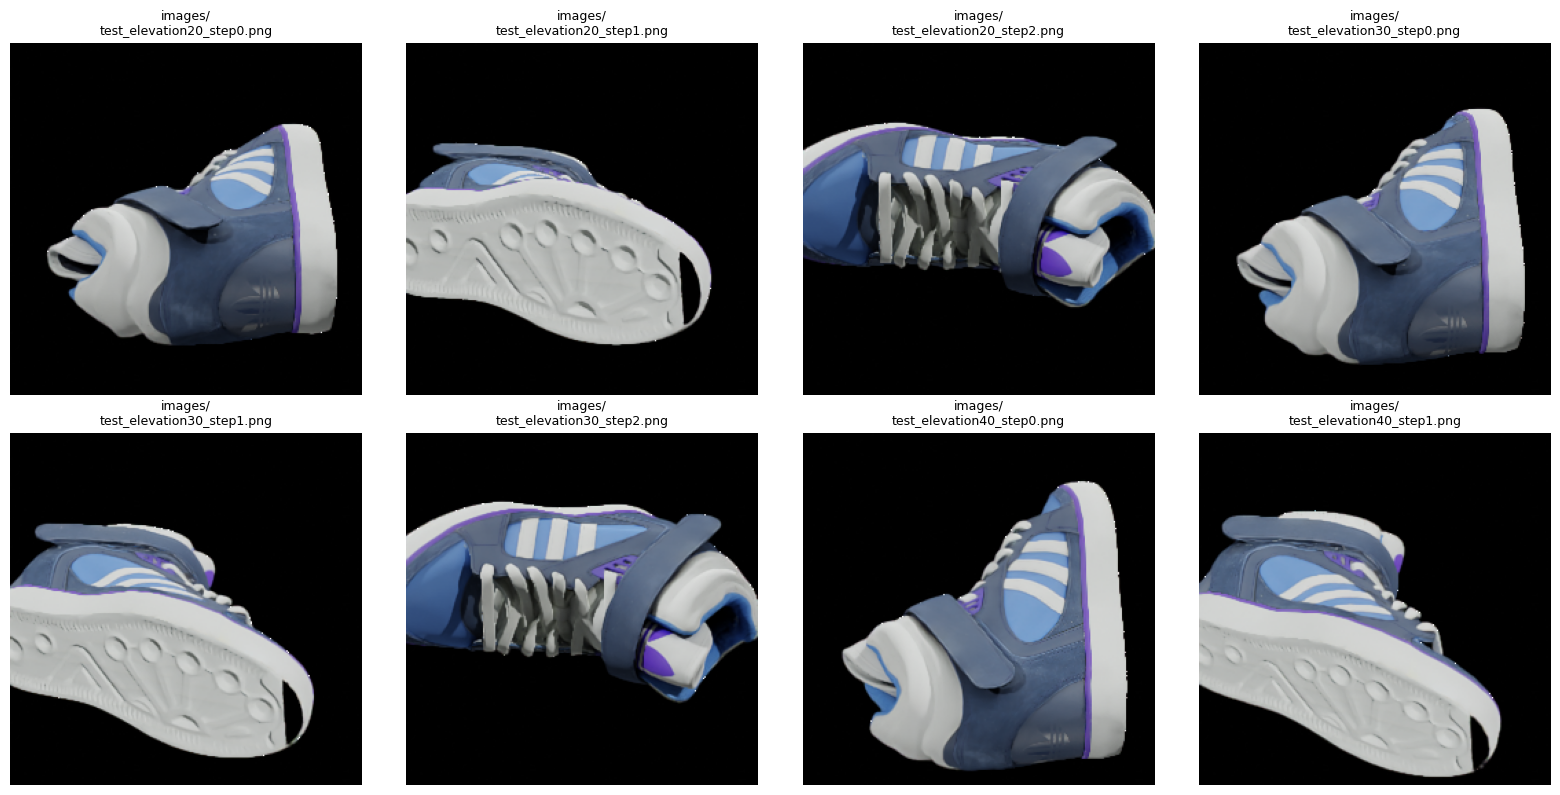


📂 Danh sách một số scene tìm thấy (5 scenes):
 - gt
 - images
 - masks
 - masks_bkup
 - pred


In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

# 1. Quét tìm tất cả file ảnh trong thư mục vừa giải nén
search_pattern = "/content/data/ood-nvs/**/*.{png,jpg,jpeg,PNG,JPG}"
image_files = []
for ext in ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG"]:
    image_files.extend(glob.glob(f"/content/data/ood-nvs/**/{ext}", recursive=True))

image_files = sorted(image_files)
print(f" Tìm thấy tổng cộng {len(image_files)} ảnh trong bộ test-set.")

# 2. Hiển thị 8 ảnh mẫu đầu tiên
if not image_files:
    print("❌ Chưa tìm thấy ảnh nào. Kiểm tra lại đường dẫn giải nén /content/data/ood-nvs.")
else:
    num_to_show = min(8, len(image_files))
    cols = 4
    rows = (num_to_show + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = axes.flatten() if num_to_show > 1 else [axes]

    for i in range(num_to_show):
        img_path = image_files[i]
        try:
            img = Image.open(img_path).convert("RGB")
            axes[i].imshow(img)
            # Rút gọn nhãn: [Tên scene] / [Tên file]
            scene_name = os.path.basename(os.path.dirname(img_path))
            file_name = os.path.basename(img_path)
            axes[i].set_title(f"{scene_name}/\n{file_name}", fontsize=9)
        except Exception as e:
            axes[i].text(0.5, 0.5, f"Lỗi đọc:\n{file_name}", ha="center")
        axes[i].axis("off")

    for j in range(num_to_show, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# 3. Liệt kê một số scene cụ thể tìm thấy
scenes = set(os.path.basename(os.path.dirname(p)) for p in image_files)
print(f"\n📂 Danh sách một số scene tìm thấy ({len(scenes)} scenes):")
for s in sorted(list(scenes))[:10]:
    print(f" - {s}")

In [ ]:
# Metric patches
import os, textwrap

PATCH_DIR = "/content/py_patches"
os.makedirs(PATCH_DIR, exist_ok=True)

sitecustomize_code = textwrap.dedent("""
    import functools
    import numpy as np
    try:
        import skimage.metrics as _skm
        _orig_ssim = _skm.structural_similarity

        @functools.wraps(_orig_ssim)
        def _safe_ssim(im1, im2, *args, **kwargs):
            # (Phien 13) Ban skimage nay KHONG con tu map multichannel=True -> channel_axis:
            # no coi ca chieu mau (vd =3) la chieu khong gian -> bao nham \"win_size exceeds
            # image extent\" du anh thuc te rat lon (vd 512x768). Phai tu chuyen doi TRUOC
            # khi goi, khong doi loi roi doan mo shape.
            if kwargs.pop('multichannel', False) and 'channel_axis' not in kwargs:
                kwargs['channel_axis'] = -1
            # Anh dang la float (vd gia tri trong [0,1]) -> ban skimage nay doi hoi
            # data_range tuong minh, neu khong se raise ValueError rieng (khong lien quan
            # win_size). Tu dien data_range=1.0 cho truong hop float pho bien nay.
            if 'data_range' not in kwargs:
                arr = np.asarray(im1)
                if np.issubdtype(arr.dtype, np.floating):
                    kwargs['data_range'] = 1.0
            try:
                return _orig_ssim(im1, im2, *args, **kwargs)
            except ValueError as e:
                if \"win_size exceeds image extent\" in str(e):
                    # Truong hop nay la anh THUC SU qua nho (hiem, khac voi loi channel_axis
                    # o tren da duoc xu ly truoc do).
                    ch_axis = kwargs.get('channel_axis', None)
                    if ch_axis is not None:
                        ch_axis = ch_axis % im1.ndim
                    spatial_shape = [s for ax, s in enumerate(im1.shape) if ax != ch_axis]
                    max_win = min(spatial_shape) if spatial_shape else min(im1.shape)
                    print(f\"[safe_ssim] Anh THUC SU qua nho de tinh SSIM: shape={im1.shape} -> tra ve 0.0\")
                    if max_win < 3:
                        return 0.0
                    win = max_win if max_win % 2 == 1 else max_win - 1
                    kwargs['win_size'] = win
                    return _orig_ssim(im1, im2, *args, **kwargs)
                raise
        _skm.structural_similarity = _safe_ssim
    except Exception as _e:
        print(f\"[sitecustomize] Khong the patch skimage ssim: {_e}\")
""")

with open(os.path.join(PATCH_DIR, "sitecustomize.py"), "w") as f:
    f.write(sitecustomize_code)

print(f"-> Created {PATCH_DIR}/sitecustomize.py (v2: tu chuyen multichannel->channel_axis + "
      f"tu dien data_range cho anh float) de va ham SSIM (skimage).")


-> Da tao /content/py_patches/sitecustomize.py (v2: tu chuyen multichannel->channel_axis + tu dien data_range cho anh float) de va ham SSIM (skimage).


## Step 4 - Feed-forward MVS Initialization and triangulization

In [ ]:
import os, subprocess, glob, shutil, sqlite3
_colmap_help_cache = {}

def _resolve_colmap_option(subcommand, candidate_flags, env):
    if subcommand not in _colmap_help_cache:
        res = subprocess.run(["colmap", subcommand, "--help"], env=env,
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        _colmap_help_cache[subcommand] = res.stdout
    help_text = _colmap_help_cache[subcommand]
    for flag in candidate_flags:
        if f"--{flag} " in help_text or f"--{flag}\n" in help_text:
            return flag
    raise RuntimeError(
        f"Không tìm thấy option nào trong {candidate_flags} ở `colmap {subcommand} --help` THẬT "
        f"(bản colmap trên máy này có thể đã đổi tên option theo cách khác nữa) -- toàn bộ help thật "
        f"để tự đối chiếu tay:\n{help_text}"
    )

def build_points3d_via_triangulation(scene_name, scene_path, sparse_dir, env):
    if shutil.which("colmap") is None:
        print(f"-> [{scene_name}] Cài COLMAP (cần feature_extractor/matcher/point_triangulator thật)...")
        subprocess.run("apt-get update -qq && apt-get install -y -qq colmap", shell=True, check=True)

    _ver = subprocess.run(["colmap", "--version"], env=env,
                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    print(f"-> [{scene_name}] colmap --version thật: {_ver.stdout.strip()}")

    images_dir_candidates = [os.path.join(scene_path, "images"), os.path.join(scene_path, "image")]
    images_dir = next((d for d in images_dir_candidates
                        if os.path.isdir(d) and glob.glob(os.path.join(d, "*"))), None)
    if images_dir is None:
        raise RuntimeError(f"[{scene_name}] Không tìm thấy thư mục ảnh thật (đã thử "
                            f"{images_dir_candidates}) để chạy feature_extractor.")

    gt_cameras = {}
    with open(os.path.join(sparse_dir, "cameras.txt")) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            p = line.split()
            gt_cameras[int(p[0])] = {"model": p[1], "width": int(p[2]), "height": int(p[3]), "params": p[4:]}
    if len(gt_cameras) != 1:
        raise RuntimeError(f"[{scene_name}] cameras.txt có {len(gt_cameras)} camera khác nhau (logic "
                            f"hiện tại chỉ xử lý đúng 1 camera dùng chung cho cả scene -- trường hợp "
                            f"nhiều camera cần code khác, chưa gặp thật nên chưa viết). Nội dung: {gt_cameras}")
    gt_cam = next(iter(gt_cameras.values()))

    gt_images = {}
    with open(os.path.join(sparse_dir, "images.txt")) as f:
        lines = f.readlines()
    i = 0
    while i < len(lines):
        line = lines[i].strip(); i += 1
        if not line or line.startswith("#"):
            continue
        p = line.split()
        gt_images[p[9]] = {"qvec": p[1:5], "tvec": p[5:8], "camera_id": int(p[8])}
        i += 1  # bỏ dòng POINTS2D
    if not gt_images:
        raise RuntimeError(f"[{scene_name}] images.txt không parse được ảnh nào tại {sparse_dir}.")

    work_dir = os.path.join(scene_path, "_triangulate_tmp")
    if os.path.isdir(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)
    db_path = os.path.join(work_dir, "database.db")

    subprocess.run(["colmap", "database_creator", "--database_path", db_path], env=env, check=True)

    res_fe = subprocess.run(["colmap", "feature_extractor",
                              "--database_path", db_path, "--image_path", images_dir,
                              "--ImageReader.single_camera", "1",
                              "--ImageReader.camera_model", gt_cam["model"],
                              "--ImageReader.camera_params", ",".join(gt_cam["params"]),
                              "--SiftExtraction.use_gpu", "0",
                              "--SiftExtraction.peak_threshold", "0.001"],
                             env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if res_fe.returncode != 0:
        raise RuntimeError(f" [{scene_name}] colmap feature_extractor lỗi:\n{res_fe.stdout[-3000:]}")

    min_inliers_flag = _resolve_colmap_option(
        "exhaustive_matcher",
        ["SiftMatching.min_num_inliers", "TwoViewGeometry.min_num_inliers"],
        env,
    )
    res_m = subprocess.run(["colmap", "exhaustive_matcher", "--database_path", db_path,
                             "--SiftMatching.use_gpu", "0",
                             f"--{min_inliers_flag}", "6"],
                            env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if res_m.returncode != 0:
        raise RuntimeError(f" [{scene_name}] colmap exhaustive_matcher lỗi (đã dùng flag "
                            f"--{min_inliers_flag}):\n{res_m.stdout[-3000:]}")

    conn = sqlite3.connect(db_path)
    db_images = conn.execute("SELECT image_id, camera_id, name FROM images").fetchall()
    conn.close()
    if not db_images:
        raise RuntimeError(f"[{scene_name}] database rỗng sau feature_extractor -- không đọc được "
                            f"ảnh nào từ {images_dir}.")
    db_name_to_id = {name: (image_id, camera_id) for image_id, camera_id, name in db_images}
    missing = [n for n in gt_images if n not in db_name_to_id]
    if missing:
        raise RuntimeError(f"[{scene_name}] {len(missing)} ảnh trong images.txt GT không khớp tên "
                            f"file trong database (vd: {missing[:5]}). Tên thật trong database: "
                            f"{[n for _, _, n in db_images][:10]}")

    manual_dir = os.path.join(work_dir, "manual")
    os.makedirs(manual_dir, exist_ok=True)
    with open(os.path.join(manual_dir, "points3D.txt"), "w") as f:
        f.write("# rỗng, theo đúng yêu cầu colmap point_triangulator (COLMAP FAQ)\n")
    with open(os.path.join(manual_dir, "cameras.txt"), "w") as f:
        any_cam_id = next(iter(db_name_to_id.values()))[1]
        f.write(f"{any_cam_id} {gt_cam['model']} {gt_cam['width']} {gt_cam['height']} "
                f"{' '.join(gt_cam['params'])}\n")
    with open(os.path.join(manual_dir, "images.txt"), "w") as f:
        for name, (image_id, camera_id) in db_name_to_id.items():
            g = gt_images[name]
            f.write(f"{image_id} {' '.join(g['qvec'])} {' '.join(g['tvec'])} {camera_id} {name}\n\n")

    tri_out = os.path.join(work_dir, "triangulated")
    os.makedirs(tri_out, exist_ok=True)
    res_t = subprocess.run(["colmap", "point_triangulator",
                             "--database_path", db_path, "--image_path", images_dir,
                             "--input_path", manual_dir, "--output_path", tri_out],
                            env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if res_t.returncode != 0:
        raise RuntimeError(f"[{scene_name}] colmap point_triangulator lỗi:\n{res_t.stdout[-3000:]}")

    for fn in ["cameras.bin", "images.bin", "points3D.bin"]:
        src_fn = os.path.join(tri_out, fn)
        if not os.path.exists(src_fn):
            raise RuntimeError(f"[{scene_name}] point_triangulator chạy xong (exit 0) nhưng thiếu "
                                f"{fn} -- nội dung thật {tri_out}: {os.listdir(tri_out)}")
        shutil.copy(src_fn, os.path.join(sparse_dir, fn))
    print(f"-> [{scene_name}] Đã triangulate points3D thật (giữ nguyên pose GT) -> {sparse_dir}")

    diag_txt_dir = os.path.join(work_dir, "diag_txt")
    os.makedirs(diag_txt_dir, exist_ok=True)
    res_diag = subprocess.run(["colmap", "model_converter", "--input_path", sparse_dir,
                                "--output_path", diag_txt_dir, "--output_type", "TXT"],
                               env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if res_diag.returncode != 0:
        raise RuntimeError(f"[{scene_name}] colmap model_converter (chẩn đoán TXT) lỗi:\n"
                            f"{res_diag.stdout[-3000:]}")
    counts = {}
    with open(os.path.join(diag_txt_dir, "images.txt")) as f:
        lines = f.readlines()
    i = 0
    while i < len(lines):
        line = lines[i].strip(); i += 1
        if not line or line.startswith("#"):
            continue
        name = line.split()[9]
        pts_line = lines[i].strip(); i += 1
        toks = pts_line.split()
        n_visible = sum(1 for j in range(2, len(toks), 3) if toks[j] != "-1")
        counts[name] = n_visible
    zero_imgs = [n for n, c in counts.items() if c == 0]
    vals = list(counts.values())
    print(f"-> [{scene_name}] Điểm points3D khả kiến/ảnh: min={min(vals)}, max={max(vals)}, "
          f"mean={sum(vals)/len(vals):.1f}, tổng {len(zero_imgs)}/{len(counts)} ảnh có 0 điểm.")
    if zero_imgs:
        print(f"⚠️ [{scene_name}] {len(zero_imgs)}/{len(counts)} ảnh có 0 điểm points3D khả kiến sau "
              f"triangulate -- sẽ dùng fallback depth range toàn cảnh (đã vá pose_utils.py). Danh sách: "
              f"{zero_imgs}")
    with open(os.path.join(sparse_dir, "_triangulate_ok.marker"), "w") as f:
        f.write("ok\n")

print("=== BƯỚС 4-ood(c): MVSGaussian feed-forward -> .ply MVS-init cho từng scene OOD ===")

CONDA_PREFIX = "/usr/local/miniconda/envs/splatformer"
PYTHON_BIN = f"{CONDA_PREFIX}/bin/python"

env = os.environ.copy()
env["CUDA_HOME"] = "/usr/local/cuda-11.8"
env["PATH"] = f"/usr/local/cuda-11.8/bin:{CONDA_PREFIX}/bin:" + env.get("PATH", "")
env["PYTHONPATH"] = "/content/py_patches:" + env.get("PYTHONPATH", "")
env["QT_QPA_PLATFORM"] = "offscreen"

scene_dataset_dir = os.path.join(OOD_TESTSET_ROOT, OOD_DATASET, "colmap")
all_scene_names = sorted(os.path.basename(p) for p in glob.glob(os.path.join(scene_dataset_dir, "*"))
                          if os.path.isdir(p))
if not all_scene_names:
    raise RuntimeError(f"Không tìm thấy scene nào trong {scene_dataset_dir}. Xem lại output BƯỚС 4-ood(a).")
scene_names_list = all_scene_names[:N_SCENES_OOD]
print(f"-> Chạy trên {len(scene_names_list)}/{len(all_scene_names)} scene: {scene_names_list}")

os.makedirs(PLY_OUTPUT_DIR, exist_ok=True)
os.chdir("/content/MVSGaussian")

_POSE_UTILS_PATH = "lib/colmap/poses/pose_utils.py"
with open(_POSE_UTILS_PATH) as _f:
    _pu_src = _f.read()
_MARKER_LINE = "        if zs.size == 0:"
_OLD_LOOP = """    for i in perm:
        vis = vis_arr[:, i]
        zs = zvals[:, i]
        zs = zs[vis==1]
        close_depth, inf_depth = np.percentile(zs, .1), np.percentile(zs, 99.9)"""
_NEW_LOOP = """    for i in perm:
        vis = vis_arr[:, i]
        zs = zvals[:, i]
        zs = zs[vis==1]
        if zs.size == 0:
            close_depth, inf_depth = np.percentile(valid_z, .1), np.percentile(valid_z, 99.9)
        else:
            close_depth, inf_depth = np.percentile(zs, .1), np.percentile(zs, 99.9)"""
if _MARKER_LINE in _pu_src:
    print(f"-> {_POSE_UTILS_PATH} đã được vá từ trước (marker cấu trúc tìm thấy) -- bỏ qua.")
elif _OLD_LOOP in _pu_src:
    _pu_src = _pu_src.replace(_OLD_LOOP, _NEW_LOOP, 1)
    with open(_POSE_UTILS_PATH, "w") as _f:
        _f.write(_pu_src)
    print(f"-> Đã vá {_POSE_UTILS_PATH}: ảnh 0-điểm dùng fallback depth range toàn cảnh thay vì crash.")
else:
    _idx = _pu_src.find("close_depth")
    raise RuntimeError(
        f"Không tìm thấy CẢ marker đã-vá (\"{_MARKER_LINE}\") LẪN đoạn code gốc cần vá trong "
        f"{_POSE_UTILS_PATH} -- thật sự khác cấu trúc đã biết, cần xem thủ công. 400 ký tự quanh "
        f"'close_depth' để đối chiếu: "
        f"{repr(_pu_src[max(0, _idx-400):_idx+400]) if _idx != -1 else '(không tìm thấy chuỗi close_depth nào trong file)'}"
    )

_grep_res = subprocess.run(
    ["grep", "-n", "-E", "imread|Image.open|cv2[.]|plt.imread|frombuffer", "-A", "2", "-B", "2",
     "lib/datasets/colmap/mvsgs.py"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
print("-> [Phiên 47] Nội dung THẬT (grep imread/Image.open/cv2/...) trong lib/datasets/colmap/mvsgs.py:")
print(_grep_res.stdout if _grep_res.stdout.strip() else "(grep không khớp dòng nào -- có thể tên hàm đọc ảnh khác, cần xem toàn bộ file)")

# UPD (Phiên 62): áp cùng cách kiểm tra theo marker cấu trúc cho patch RGBA->RGB, đồng bộ với fix
# ở pose_utils.py phía trên -- lý do giống hệt (comment không nên là điều kiện idempotent).
_MVSGS_PATH = "lib/datasets/colmap/mvsgs.py"
with open(_MVSGS_PATH) as _f:
    _mvsgs_src = _f.read()
_MVSGS_MARKER = "        if img.ndim == 3 and img.shape[-1] == 4:"
_OLD_READ = "        img = (np.array(imageio.imread(image_path))).astype(np.float32)"
_NEW_READ = (
    "        img = np.array(imageio.imread(image_path))\n"
    "        if img.ndim == 3 and img.shape[-1] == 4:\n"
    "            img = img[..., :3]\n"
    "        img = img.astype(np.float32)"
)
if _MVSGS_MARKER in _mvsgs_src:
    print(f"-> {_MVSGS_PATH} đã được vá từ trước (marker cấu trúc tìm thấy) -- bỏ qua.")
elif _OLD_READ in _mvsgs_src:
    _mvsgs_src = _mvsgs_src.replace(_OLD_READ, _NEW_READ, 1)
    with open(_MVSGS_PATH, "w") as _f:
        _f.write(_mvsgs_src)
    print(f"-> Đã vá {_MVSGS_PATH}: ép RGBA->RGB ngay sau imageio.imread(), trước astype(np.float32) "
          f"trong read_image().")
else:
    raise RuntimeError(f"Không tìm thấy CẢ marker đã-vá LẪN đoạn code gốc cần vá trong {_MVSGS_PATH} "
                        f"(khác bản đã grep ở Phiên 47) -- cần xem lại thủ công trước khi tiếp tục.")

mvs_ply_paths = {}
for scene_name in scene_names_list:
    scene_path = os.path.join(scene_dataset_dir, scene_name)
    sparse_dir = os.path.join(scene_path, "sparse", "0")
    bin_files = ["cameras.bin", "images.bin", "points3D.bin"]
    txt_files = ["cameras.txt", "images.txt", "points3D.txt"]
    has_bin = all(os.path.exists(os.path.join(sparse_dir, f)) for f in bin_files)
    has_txt = all(os.path.exists(os.path.join(sparse_dir, f)) for f in txt_files)
    ok_marker = os.path.join(sparse_dir, "_triangulate_ok.marker")
    if has_bin and not has_txt and not os.path.exists(ok_marker):
        print(f"-> [{scene_name}] Phát hiện .bin cũ chưa qua marker xác nhận (có thể sót từ lần crash "
              f"trước) -- xoá và build lại triangulate từ đầu.")
        for f in bin_files:
            p = os.path.join(sparse_dir, f)
            if os.path.exists(p):
                os.remove(p)
        pb_stale = os.path.join(scene_path, "poses_bounds.npy")
        if os.path.exists(pb_stale):
            os.remove(pb_stale)
        has_bin = False
    if not has_bin and not has_txt:
        has_gt_pose_only = (os.path.exists(os.path.join(sparse_dir, "cameras.txt")) and
                             os.path.exists(os.path.join(sparse_dir, "images.txt")))
        if not has_gt_pose_only:
            actual_files = sorted(os.listdir(sparse_dir)) if os.path.isdir(sparse_dir) else None
            raise RuntimeError(f"Scene {scene_name}: thiếu cả cameras.txt/images.txt (không chỉ "
                                f"points3D) tại {sparse_dir} -- không đủ để triangulate. Nội dung thật: "
                                f"{actual_files}")
        build_points3d_via_triangulation(scene_name, scene_path, sparse_dir, env)
        has_bin = all(os.path.exists(os.path.join(sparse_dir, f)) for f in bin_files)
        if not has_bin:
            raise RuntimeError(f"Scene {scene_name}: build_points3d_via_triangulation chạy xong "
                                f"nhưng vẫn thiếu .bin tại {sparse_dir} -- xem log phía trên.")
    if not has_bin and has_txt:
        if shutil.which("colmap") is None:
            print("-> Cài COLMAP (chỉ để dùng model_converter đổi .txt->.bin, KHÔNG chạy reconstruction)...")
            subprocess.run("apt-get update -qq && apt-get install -y -qq colmap", shell=True, check=True)
        res_conv = subprocess.run(["colmap", "model_converter", "--input_path", sparse_dir,
                                    "--output_path", sparse_dir, "--output_type", "BIN"],
                                   env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        if res_conv.returncode != 0:
            print(f" [{scene_name}] colmap model_converter lỗi (exit {res_conv.returncode}), stderr thật:\n{res_conv.stdout[-3000:]}")
            raise RuntimeError(f"[{scene_name}] colmap model_converter thất bại — xem log stderr phía trên.")
        print(f"-> [{scene_name}] Đã convert cameras.txt/images.txt/points3D.txt -> .bin")

    poses_bounds_path = os.path.join(scene_path, "poses_bounds.npy")
    if not os.path.exists(poses_bounds_path):
        print(f"-> [{scene_name}] Sinh poses_bounds.npy từ sparse/0 (imgs2poses.py, tự bỏ qua colmap "
              f"reconstruction vì sparse/0 đã đủ .bin)...")
        res_pb = subprocess.run([PYTHON_BIN, "lib/colmap/imgs2poses.py", "-s", scene_path],
                                 env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        if res_pb.returncode != 0:
            raise RuntimeError(f"[{scene_name}] lib/colmap/imgs2poses.py lỗi:\n{res_pb.stdout[-3000:]}")
        if not os.path.exists(poses_bounds_path):
            raise RuntimeError(f"[{scene_name}] imgs2poses.py chạy xong (exit 0) nhưng không thấy "
                                f"{poses_bounds_path} -- nội dung thật {scene_path}: "
                                f"{os.listdir(scene_path)}")
        print(f"-> [{scene_name}] Đã sinh {poses_bounds_path}")

    scene_ply_dir = os.path.join(PLY_OUTPUT_DIR, scene_name)
    os.makedirs(scene_ply_dir, exist_ok=True)
    cmd = [
        PYTHON_BIN, "run.py",
        "--type", "evaluate",
        "--cfg_file", "configs/mvsgs/colmap_eval.yaml",
        "test_dataset.data_root", scene_dataset_dir,
        "test_dataset.scene", scene_name,
        "save_ply", "True",
        "dir_ply", scene_ply_dir,
    ]
    print(f"\n-> [{scene_name}] Chạy MVSGaussian evaluate...")
    res = subprocess.run(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    print(res.stdout[-2000:])
    if res.returncode != 0:
        raise RuntimeError(f"[{scene_name}] MVSGaussian evaluate thất bại — xem log phía trên.")
    found = glob.glob(f"{scene_ply_dir}/**/*.ply", recursive=True)
    if not found:
        raise RuntimeError(f" [{scene_name}] Không tìm thấy .ply nào được sinh ra.")
    mvs_ply_paths[scene_name] = found[0]
    print(f"✅ [{scene_name}] .ply: {found[0]}")

print(f"\n✅ Xong BƯỚС 4-ood(c): sinh .ply cho {len(mvs_ply_paths)} scene.")

=== BƯỚС 4-ood(c): MVSGaussian feed-forward -> .ply MVS-init cho từng scene OOD ===
-> Chạy trên 10/20 scene: ['02691156-2628b6cfcf1a53465569af4484881d20-10', '02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10', '02958343-1f6ce6dd6720436642534f02c8e8b5ac-10', '02958343-9f703e578b4b36295b74572d48ff6382-10', '03001627-1c199ef7e43188887215a1e3ffbff428-10', '03001627-20c6158bbeb2735ed1dcc55e36186e4e-10', '03001627-bbab666132885a14ea96899baeb81e22-10', '03046257-108b7ee0ca90a60cdb98a62365dd8bc1-10', '03046257-b602321e87ba6ffedce1f8ab000da922-10', '03928116-71bdb3a149c93be6834096795cc3cf10-10']
-> Đã vá lib/colmap/poses/pose_utils.py: ảnh 0-điểm dùng fallback depth range toàn cảnh thay vì crash.
-> [Phiên 47] Nội dung THẬT (grep imread/Image.open/cv2/...) trong lib/datasets/colmap/mvsgs.py:
212-    def read_image(self, scene, view_idx):
213-        image_path = os.path.join(self.data_root, scene['scene_name'], 'images', scene['image_names'][view_idx])
214:        img = (np.array(imageio.imread(im

In [ ]:
import os, glob, subprocess

eval_mvsinit_script = """
import os, glob, cv2, torch
import numpy as np
import pandas as pd
from PIL import Image
from plyfile import PlyData
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
import lpips

print("=== 📊 BÁO CÁO THỐNG KÊ CHI TIẾT MVS-INIT (BIẾN THỂ ALPHA) ===")

colmap_root = "/content/data/ood-nvs/test-set/shapenetOOD/colmap"
mvs_output_dir = "/content/mvs_output_ood"
loss_fn_vgg = lpips.LPIPS(net='vgg').cuda()

scenes = sorted([
    os.path.basename(p) for p in glob.glob(os.path.join(colmap_root, "*_mvsinit_alpha"))
    if os.path.isdir(p) and "_mvsinit_mvsinit" not in p
])

rows_3d = []
rows_2d = []

for idx, sc_alpha in enumerate(scenes):
    base_name = sc_alpha.replace("_mvsinit_alpha", "")

    # ---------------- 1. THỐNG KÊ 3D POINT CLOUD ----------------
    pts_txt = os.path.join(colmap_root, sc_alpha, "sparse", "0", "points3D.txt")
    orig_mvs_dir = os.path.join(colmap_root, base_name + "_mvsinit", "sparse", "0")
    orig_pts_txt = os.path.join(orig_mvs_dir, "points3D.txt.orig_unfiltered_backup")
    if not os.path.exists(orig_pts_txt):
        orig_pts_txt = os.path.join(orig_mvs_dir, "points3D.txt")

    num_pts_alpha = 0
    bbox_diag = 0.0
    if os.path.exists(pts_txt):
        pts = []
        with open(pts_txt, "r") as f:
            for line in f:
                if line.startswith("#") or not line.strip(): continue
                p = line.split()
                pts.append([float(p[1]), float(p[2]), float(p[3])])
        if pts:
            pts_np = np.array(pts)
            num_pts_alpha = len(pts_np)
            bbox_min = pts_np.min(axis=0)
            bbox_max = pts_np.max(axis=0)
            bbox_diag = np.linalg.norm(bbox_max - bbox_min)

    num_pts_orig = 0
    if os.path.exists(orig_pts_txt):
        with open(orig_pts_txt, "r") as f:
            num_pts_orig = sum(1 for line in f if not line.startswith("#") and line.strip())

    filter_ratio = (num_pts_alpha / num_pts_orig * 100) if num_pts_orig > 0 else 100.0

    rows_3d.append({
        "Scene": base_name[:22] + "...",
        "Điểm MVS gốc": num_pts_orig,
        "Điểm MVS Alpha": num_pts_alpha,
        "Tỉ lệ giữ lại (%)": round(filter_ratio, 1),
        "Đường kính BBox (3D)": round(bbox_diag, 2)
    })

    # ---------------- 2. ĐÁNH GIÁ 2D METRICS (NẾU CÓ RENDER MVSGAUSSIAN) ----------------
    # Kiểm tra các ảnh render nội bộ từ MVSGaussian trong thư mục mvs_output_ood
    mvs_renders = glob.glob(os.path.join(mvs_output_dir, base_name, "**", "*_pred.png"), recursive=True) + \
                  glob.glob(os.path.join(mvs_output_dir, base_name, "**", "vis", "*.png"), recursive=True)

    if mvs_renders:
        psnr_list, ssim_list, lpips_list = [], [], []
        for p_img in mvs_renders[:10]:
            gt_p = p_img.replace("_pred.png", "_gt.png")
            if os.path.exists(gt_p):
                im_p = np.array(Image.open(p_img).convert("RGB")).astype(np.float32) / 255.0
                im_g = np.array(Image.open(gt_p).convert("RGB")).astype(np.float32) / 255.0
                psnr_list.append(psnr_fn(im_g, im_p, data_range=1.0))
                ssim_list.append(ssim_fn(im_g, im_p, channel_axis=-1, data_range=1.0))

                tg = torch.from_numpy(im_g).permute(2, 0, 1).unsqueeze(0).cuda() * 2.0 - 1.0
                tp = torch.from_numpy(im_p).permute(2, 0, 1).unsqueeze(0).cuda() * 2.0 - 1.0
                with torch.no_grad():
                    lpips_list.append(loss_fn_vgg(tg, tp).item())
        if psnr_list:
            rows_2d.append({
                "Scene": base_name[:22] + "...",
                "PSNR (dB)": round(float(np.mean(psnr_list)), 2),
                "SSIM": round(float(np.mean(ssim_list)), 4),
                "LPIPS": round(float(np.mean(lpips_list)), 4)
            })

df_3d = pd.DataFrame(rows_3d)
print("\\n1. 🌐 ĐẶC TÍNH HÌNH HỌC KHỞI TẠO 3D (MVS-INIT)")
print(df_3d.to_string(index=False))

if rows_2d:
    df_2d = pd.DataFrame(rows_2d)
    print("\\n2. 🖼️ CHẤT LƯỢNG RENDER 2D THUẦN TỪ MVSGAUSSIAN")
    print(df_2d.to_string(index=False))
    print(f"\\n-> Trung bình 2D: PSNR={df_2d['PSNR (dB)'].mean():.2f} dB, SSIM={df_2d['SSIM'].mean():.4f}, LPIPS={df_2d['LPIPS'].mean():.4f}")
else:
    print("\\n2. ℹ️ MVSGaussian chạy ở chế độ chỉ export .ply (chưa lưu cache ảnh render 2D riêng lẻ).")

df_3d.to_csv("/content/mvsinit_stats_alpha.csv", index=False)
print("\\n✅ Đã lưu kết quả tại /content/mvsinit_stats_alpha.csv")
"""

with open("/content/run_eval_mvsinit.py", "w") as f:
    f.write(eval_mvsinit_script)

CONDA_PYTHON = "/usr/local/miniconda/envs/splatformer/bin/python"
res = subprocess.run([CONDA_PYTHON, "/content/run_eval_mvsinit.py"], text=True, capture_output=True)
print(res.stdout)
if res.stderr and res.returncode != 0:
    print("Lỗi:\n", res.stderr)

=== 📊 BÁO CÁO THỐNG KÊ CHI TIẾT MVS-INIT (BIẾN THỂ ALPHA) ===
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /usr/local/miniconda/envs/splatformer/lib/python3.10/site-packages/lpips/weights/v0.1/vgg.pth

1. 🌐 ĐẶC TÍNH HÌNH HỌC KHỞI TẠO 3D (MVS-INIT)
                    Scene  Điểm MVS gốc  Điểm MVS Alpha  Tỉ lệ giữ lại (%)  Đường kính BBox (3D)
02691156-2628b6cfcf1a5...          5627            1928               34.3                  1.23
02933112-d6138b5bee8f0...           809             141               17.4                  2.12
02958343-1f6ce6dd67204...          1839            1082               58.8                  1.61
02958343-9f703e578b4b3...           922             241               26.1                  1.81
03001627-1c199ef7e4318...          1319             381               28.9                  1.88

2. ℹ️ MVSGaussian chạy ở chế độ chỉ export .ply (chưa lưu cache ảnh render 2D riêng lẻ).

✅ Đã lưu kết quả tại /content/mvs

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plyfile"], capture_output=True, text=True)
if r.returncode != 0:
    raise RuntimeError(f"❌ pip install plyfile thất bại:\n{r.stderr}")

import os, shutil
from plyfile import PlyData
import numpy as np

print("=== BƯỚС 4-ood(d): convert .ply MVS-init -> points3D.txt, tạo scene _mvsinit song song ===")

mvsinit_scene_names = {}  # scene_name -> mvsinit_scene_dir
for scene_name, ply_path in mvs_ply_paths.items():
    src_scene_dir = os.path.join(scene_dataset_dir, scene_name)
    src_sparse_dir = os.path.join(src_scene_dir, "sparse", "0")
    mvsinit_scene_dir = src_scene_dir + "_mvsinit"
    mvsinit_sparse_dir = os.path.join(mvsinit_scene_dir, "sparse", "0")
    mvsinit_images_dir = os.path.join(mvsinit_scene_dir, "images")
    os.makedirs(mvsinit_sparse_dir, exist_ok=True)

    # cameras/images GIỮ NGUYÊN pose gốc (copy cả 2 dạng nếu có, GS.py/nerfstudio đọc được cả .txt/.bin)
    for fname in ["cameras.txt", "images.txt", "cameras.bin", "images.bin"]:
        src_f = os.path.join(src_sparse_dir, fname)
        if os.path.exists(src_f):
            shutil.copy2(src_f, os.path.join(mvsinit_sparse_dir, fname))

    src_images_dir = os.path.join(src_scene_dir, "images")
    if not os.path.exists(mvsinit_images_dir) and os.path.isdir(src_images_dir):
        os.makedirs(mvsinit_images_dir, exist_ok=True)
        for fname in os.listdir(src_images_dir):
            link_path = os.path.join(mvsinit_images_dir, fname)
            if not os.path.exists(link_path):
                os.symlink(os.path.join(src_images_dir, fname), link_path)

    ply = PlyData.read(ply_path)
    v = ply["vertex"].data
    xyz = np.stack([v["x"], v["y"], v["z"]], axis=1).astype(np.float64)
    names = v.dtype.names
    if all(c in names for c in ("red", "green", "blue")):
        rgb = np.stack([v["red"], v["green"], v["blue"]], axis=1).astype(np.int32)
    else:
        print(f"-> [{scene_name}] .ply không có field red/green/blue, dùng màu xám mặc định")
        rgb = np.full((xyz.shape[0], 3), 128, dtype=np.int32)

    with open(os.path.join(mvsinit_sparse_dir, "points3D.txt"), "w") as f:
        f.write("# 3D point list with one line of data per point:\n")
        f.write("#   POINT3D_ID, X, Y, Z, R, G, B, ERROR, TRACK[] as (IMAGE_ID, POINT2D_IDX)\n")
        f.write(f"# Number of points: {xyz.shape[0]}, mean track length: 0\n")
        for i in range(xyz.shape[0]):
            x, y, z = xyz[i]
            r, g, b = rgb[i]
            f.write(f"{i} {x} {y} {z} {r} {g} {b} 1.0\n")

    old_bin = os.path.join(mvsinit_sparse_dir, "points3D.bin")
    if os.path.exists(old_bin):
        os.remove(old_bin)

    mvsinit_scene_names[scene_name] = mvsinit_scene_dir
    print(f"✅ [{scene_name}] Đã ghi {xyz.shape[0]} điểm MVS-init -> {mvsinit_scene_dir}")

print(f"\n✅ Xong BƯỚС 4-ood(d): {len(mvsinit_scene_names)} scene có bản _mvsinit song song bản gốc.")


=== BƯỚС 4-ood(d): convert .ply MVS-init -> points3D.txt, tạo scene _mvsinit song song ===
✅ [02691156-2628b6cfcf1a53465569af4484881d20-10] Đã ghi 5623 điểm MVS-init -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit
✅ [02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10] Đã ghi 704 điểm MVS-init -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10_mvsinit
✅ [02958343-1f6ce6dd6720436642534f02c8e8b5ac-10] Đã ghi 1324 điểm MVS-init -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-1f6ce6dd6720436642534f02c8e8b5ac-10_mvsinit
✅ [02958343-9f703e578b4b36295b74572d48ff6382-10] Đã ghi 994 điểm MVS-init -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-9f703e578b4b36295b74572d48ff6382-10_mvsinit
✅ [03001627-1c199ef7e43188887215a1e3ffbff428-10] Đã ghi 902 điểm MVS-init -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/03001627-1c199ef7e43188887215a1e3ffbff428-10_mvsinit
✅ [0300

## Step 5 - Alpha-masked point cloud filtering

In [ ]:
import os, sys, glob, shutil, subprocess
import numpy as np

print("=== BƯỚС 4-ood(y): Ghi biến thể chỉ-alpha cho toàn bộ scene ===")

MVSGAUSSIAN_REPO = "/content/MVSGaussian"
if MVSGAUSSIAN_REPO not in sys.path:
    sys.path.insert(0, MVSGAUSSIAN_REPO)
import fusion as F

scenes = globals().get("scene_names_list")
if not scenes:
    raise RuntimeError("❌ Không thấy scene_names_list -- chạy lại BƯỚС4-ood(c) trước.")

ERODE_PX = 3
ALPHA_SUFFIX = "_mvsinit_alpha"   # tên thư mục mới, KHÔNG trùng "_mvsinit" gốc


def alpha_mask_for(scene, name, hw):
    orig_img_dir = os.path.join(COLMAP_ROOT_OOD, scene, "images")
    image_names = sorted(f for f in os.listdir(orig_img_dir) if ('.png' in f) or ('.jpg' in f) or ('.JPG' in f))
    tar_view = int(name.rsplit("_", 2)[1])
    from PIL import Image
    import cv2
    arr = np.array(Image.open(os.path.join(orig_img_dir, image_names[tar_view])))
    if arr.ndim != 3 or arr.shape[-1] != 4:
        raise RuntimeError(f"❌ [{scene}] ảnh view {tar_view} không có alpha.")
    h, w = hw
    a = cv2.resize(arr[..., 3], (w, h), interpolation=cv2.INTER_NEAREST) > 127
    if ERODE_PX > 0:
        a = cv2.erode(a.astype(np.uint8), np.ones((2 * ERODE_PX + 1, 2 * ERODE_PX + 1), np.uint8)) > 0
    return a


def load_views(scene):
    sdir = os.path.join(PLY_OUTPUT_DIR, scene, scene)
    views = []
    for p in sorted(glob.glob(os.path.join(sdir, "images", "*.png"))):
        name = os.path.basename(p)[:-4]
        K, E = F.read_camera_parameters(os.path.join(sdir, "cam", name + ".txt"))
        views.append(dict(name=name, K=K, E=E,
                          img=F.read_img(p),
                          depth=F.read_pfm(os.path.join(sdir, "depth", name + ".pfm"))[0]))
    return views


def fuse_alpha_only(scene, views):
    """Y hệt fusion() gốc (mọi view làm cả ref lẫn src, ngưỡng gốc), chỉ thêm alpha."""
    xyz_all, rgb_all = [], []
    for ref in views:
        srcs = [v for v in views if v is not ref]
        pairs = []
        for src in srcs:
            d_rep, x2d, y2d, _, _ = F.reproject_with_depth(ref["depth"], ref["K"], ref["E"], src["depth"], src["K"], src["E"])
            h, w = ref["depth"].shape
            xr, yr = np.meshgrid(np.arange(w), np.arange(h))
            with np.errstate(invalid="ignore", divide="ignore"):
                dist = np.sqrt((x2d - xr) ** 2 + (y2d - yr) ** 2).astype(np.float32)
                rel = (np.abs(d_rep - ref["depth"]) / ref["depth"]).astype(np.float32)
            pairs.append(dict(dist=dist, rel=rel, d_rep=d_rep))
        mask = np.zeros(ref["depth"].shape, bool)
        with np.errstate(invalid="ignore"):
            for i in range(F.s, len(pairs) + 1):
                cnt = sum(((p["dist"] < i * F.dist_base) & (p["rel"] < i * F.rel_diff_base)).astype(np.int32) for p in pairs)
                mask |= cnt >= i
        h, w = ref["depth"].shape
        alpha = alpha_mask_for(scene, ref["name"], (h, w))
        final = mask & alpha & np.isfinite(ref["depth"]) & (ref["depth"] > 0)
        sum_d = ref["depth"].copy(); cnt = np.ones(ref["depth"].shape, np.int32)
        with np.errstate(invalid="ignore"):
            for p in pairs:
                m10 = (p["dist"] < 10 * F.dist_base) & (p["rel"] < 10 * F.rel_diff_base)
                sum_d = sum_d + np.where(m10, p["d_rep"], 0); cnt = cnt + m10
        depth_avg = sum_d / cnt
        xs, ys = np.meshgrid(np.arange(w), np.arange(h))
        x, y, d = xs[final], ys[final], depth_avg[final]
        xyz_ref = np.linalg.inv(ref["K"]) @ (np.vstack((x, y, np.ones_like(x))) * d)
        xyz_w = (np.linalg.inv(ref["E"]) @ np.vstack((xyz_ref, np.ones_like(x))))[:3].T
        xyz_all.append(xyz_w.astype(np.float32))
        rgb_all.append((ref["img"][final] * 255).astype(np.uint8))
    if not xyz_all:
        return np.zeros((0, 3), np.float32), np.zeros((0, 3), np.uint8)
    return np.concatenate(xyz_all), np.concatenate(rgb_all)


def write_points3D_txt(path, xyz, rgb):
    with open(path, "w") as f:
        f.write("# 3D point list with one line of data per point:\n")
        f.write("#   POINT3D_ID, X, Y, Z, R, G, B, ERROR, TRACK[] as (IMAGE_ID, POINT2D_IDX)\n")
        f.write(f"# Number of points: {len(xyz)}, mean track length: 0\n")
        for i, (p, c) in enumerate(zip(xyz, rgb), start=1):
            f.write(f"{i} {p[0]:.6f} {p[1]:.6f} {p[2]:.6f} {int(c[0])} {int(c[1])} {int(c[2])} 1.0\n")


colmap_bin = shutil.which("colmap")
print(f"-> colmap CLI: {'tìm thấy' if colmap_bin else 'KHÔNG thấy trong PATH -- sẽ bỏ qua bước txt->bin, TỰ chạy lại đoạn convert ở ô e sau'}")

summary = []
for scene in scenes:
    orig = os.path.join(COLMAP_ROOT_OOD, scene)
    dst = os.path.join(COLMAP_ROOT_OOD, scene + ALPHA_SUFFIX)
    sparse_0 = os.path.join(dst, "sparse", "0")
    os.makedirs(sparse_0, exist_ok=True)

    img_dst = os.path.join(dst, "images")
    img_src = os.path.join(orig, "images")
    if not os.path.exists(img_dst) and os.path.exists(img_src):
        os.symlink(img_src, img_dst)

    for fn in ["cameras.txt", "images.txt", "cameras.bin", "images.bin"]:
        src_f = os.path.join(orig, "sparse", "0", fn)
        dst_f = os.path.join(sparse_0, fn)
        if os.path.exists(src_f) and not os.path.exists(dst_f):
            shutil.copy2(src_f, dst_f)

    views = load_views(scene)
    xyz, rgb = fuse_alpha_only(scene, views)
    if len(xyz) == 0:
        raise RuntimeError(f"[{scene}] Fusion (alpha) ra 0 điểm -- kiểm tra lại alpha/depth trước khi tiếp tục.")
    write_points3D_txt(os.path.join(sparse_0, "points3D.txt"), xyz, rgb)

    if colmap_bin:
        r = subprocess.run(["colmap", "model_converter", "--input_path", sparse_0,
                             "--output_path", sparse_0, "--output_type", "BIN"],
                            capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"[{scene}] colmap model_converter thất bại:\n{r.stderr[-2000:]}")

    summary.append((scene, len(xyz)))
    print(f"[{scene}] {len(xyz)} điểm -> {dst}")

print("\n=== Tổng kết ===")
for scene, n in summary:
    print(f"  {scene}: {n} điểm")
print(f"\n Xong BƯỚС4-ood(y): {len(summary)} scene, thư mục '<scene>{ALPHA_SUFFIX}' đã sẵn sàng.")
print(f"\nBước tiếp theo: trong BƯỚС4-ood(e) (đoạn chuẩn hoá bạn đã có), đổi mẫu glob")
print(f'   glob.glob(os.path.join(colmap_root, "*_mvsinit"))')
print(f"thành (chạy thêm, không thay hẳn):")
print(f'   glob.glob(os.path.join(colmap_root, "*{ALPHA_SUFFIX}"))')
print(f"rồi chạy lại đúng đoạn code đó 1 lần nữa cho các thư mục mới này (nếu colmap CLI không có sẵn ở")
print(f"đây thì bước txt->bin sẽ chạy trong chính đoạn ô e đó, không sao). Sau đó trỏ scene_names_list /")
print(f"đường dẫn train ở BƯỚС4-ood(e) sang hậu tố '{ALPHA_SUFFIX}' thay vì '_mvsinit' để train biến thể này.")


=== BƯỚС 4-ood(y): Ghi biến thể chỉ-alpha cho toàn bộ scene ===
-> colmap CLI: tìm thấy
✅ [02691156-2628b6cfcf1a53465569af4484881d20-10] 1927 điểm -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha
✅ [02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10] 63 điểm -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10_mvsinit_alpha
✅ [02958343-1f6ce6dd6720436642534f02c8e8b5ac-10] 654 điểm -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-1f6ce6dd6720436642534f02c8e8b5ac-10_mvsinit_alpha
✅ [02958343-9f703e578b4b36295b74572d48ff6382-10] 221 điểm -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/02958343-9f703e578b4b36295b74572d48ff6382-10_mvsinit_alpha
✅ [03001627-1c199ef7e43188887215a1e3ffbff428-10] 165 điểm -> /content/data/ood-nvs/test-set/shapenetOOD/colmap/03001627-1c199ef7e43188887215a1e3ffbff428-10_mvsinit_alpha
✅ [03001627-20c6158bbeb2735ed1dcc55e36186e4e-10] 141 điểm -> /

## Step 6 - 3D Point cloud and multi-view rendering

In [ ]:
import plotly.graph_objects as go
import numpy as np

def read_colmap_points3d(txt_path):
    coords, colors = [], []
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split()
            # X, Y, Z
            coords.append([float(parts[1]), float(parts[2]), float(parts[3])])
            # R, G, B
            colors.append(f"rgb({parts[4]},{parts[5]},{parts[6]})")
    return np.array(coords), colors

scene = "02691156-2628b6cfcf1a53465569af4484881d20-10"
alpha_path = f"/content/data/ood-nvs/test-set/shapenetOOD/colmap/{scene}_mvsinit_alpha/sparse/0/points3D.txt"

xyz, rgb = read_colmap_points3d(alpha_path)

fig = go.Figure(data=[go.Scatter3d(
    x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2],
    mode='markers',
    marker=dict(size=2.5, color=rgb, opacity=0.9)
)])

fig.update_layout(
    title=f"Point Cloud of Alpha variant: {scene} ({len(xyz)} điểm)",
    scene=dict(
        aspectmode='data',
        xaxis=dict(showbackground=False),
        yaxis=dict(showbackground=False),
        zaxis=dict(showbackground=False),
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    template="plotly_dark"
)
fig.show()

🚀 Đang render point cloud 3D cho 5 scenes...


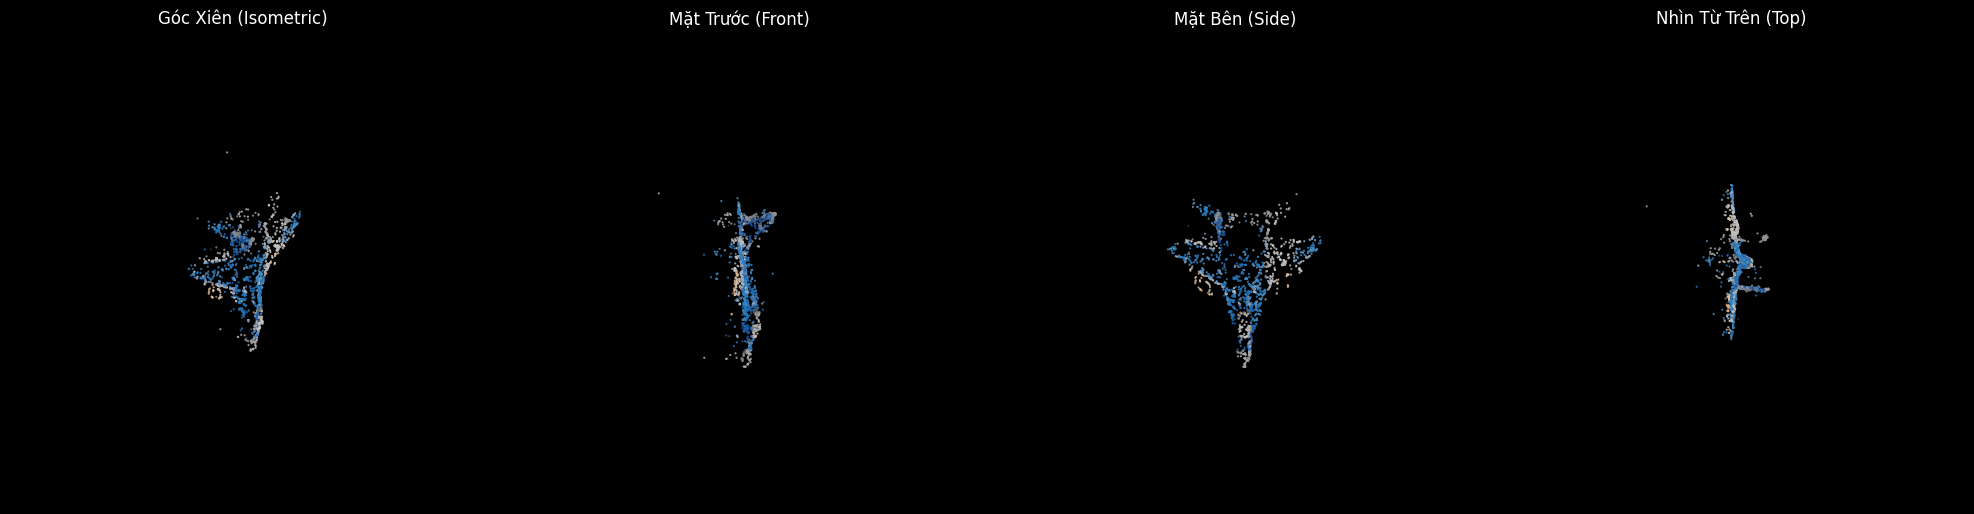

✅ Đã lưu ảnh đa góc nhìn (1928 points) tại: /content/pointcloud_renders_alpha/02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha_views.png


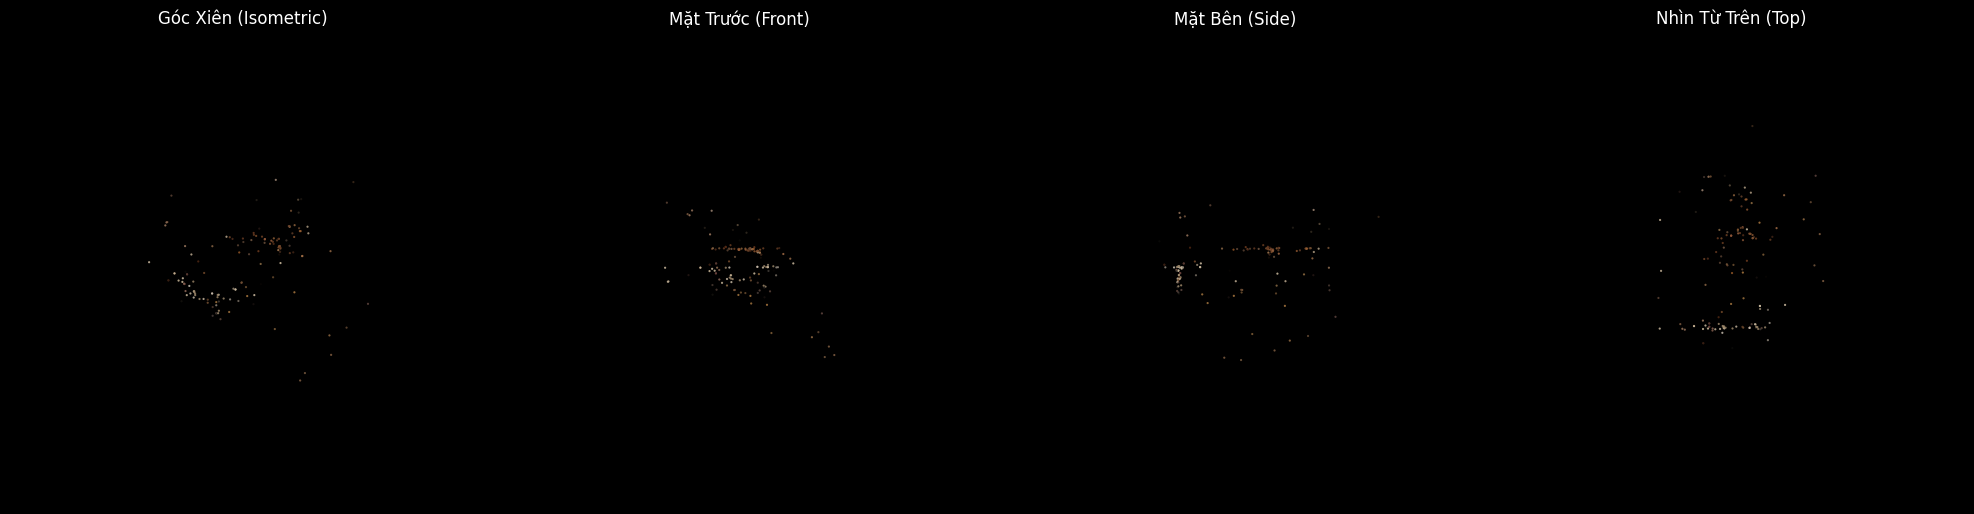

✅ Đã lưu ảnh đa góc nhìn (141 points) tại: /content/pointcloud_renders_alpha/02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10_mvsinit_alpha_views.png


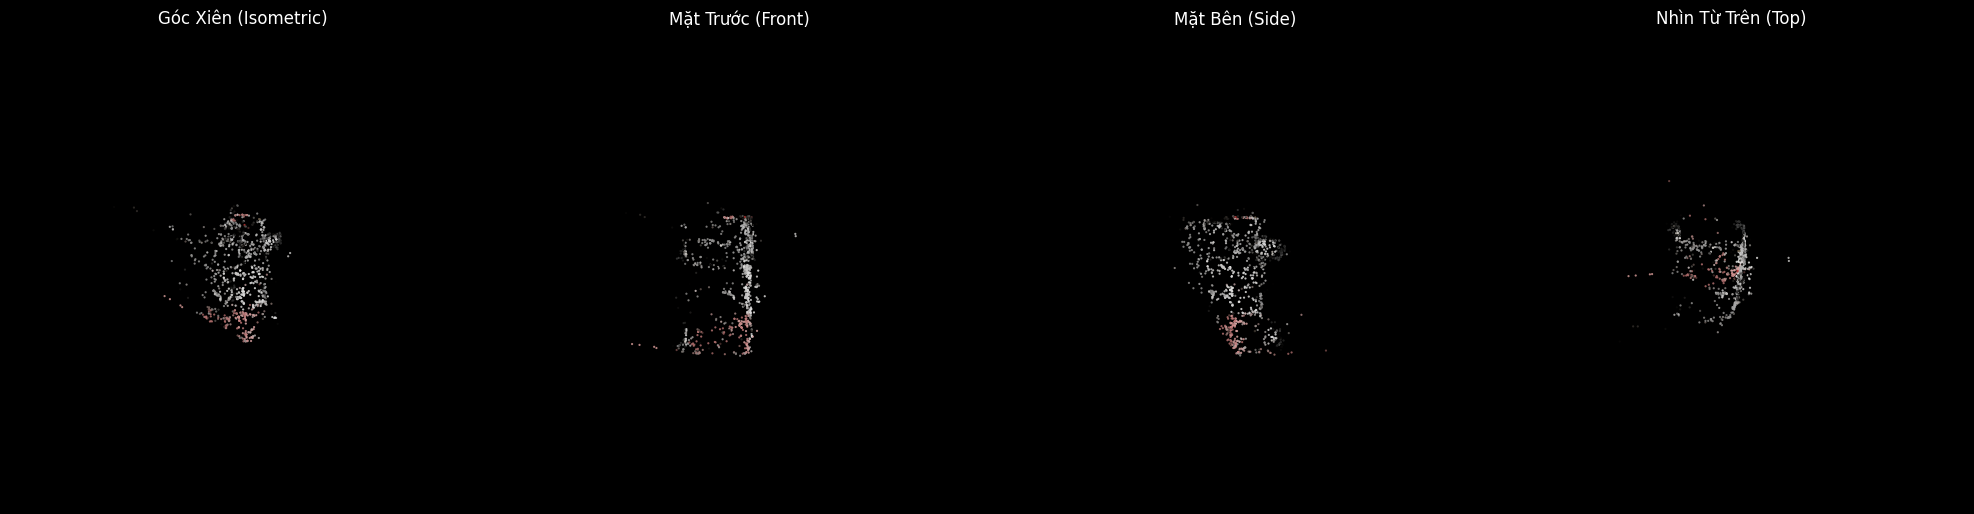

✅ Đã lưu ảnh đa góc nhìn (1082 points) tại: /content/pointcloud_renders_alpha/02958343-1f6ce6dd6720436642534f02c8e8b5ac-10_mvsinit_alpha_views.png


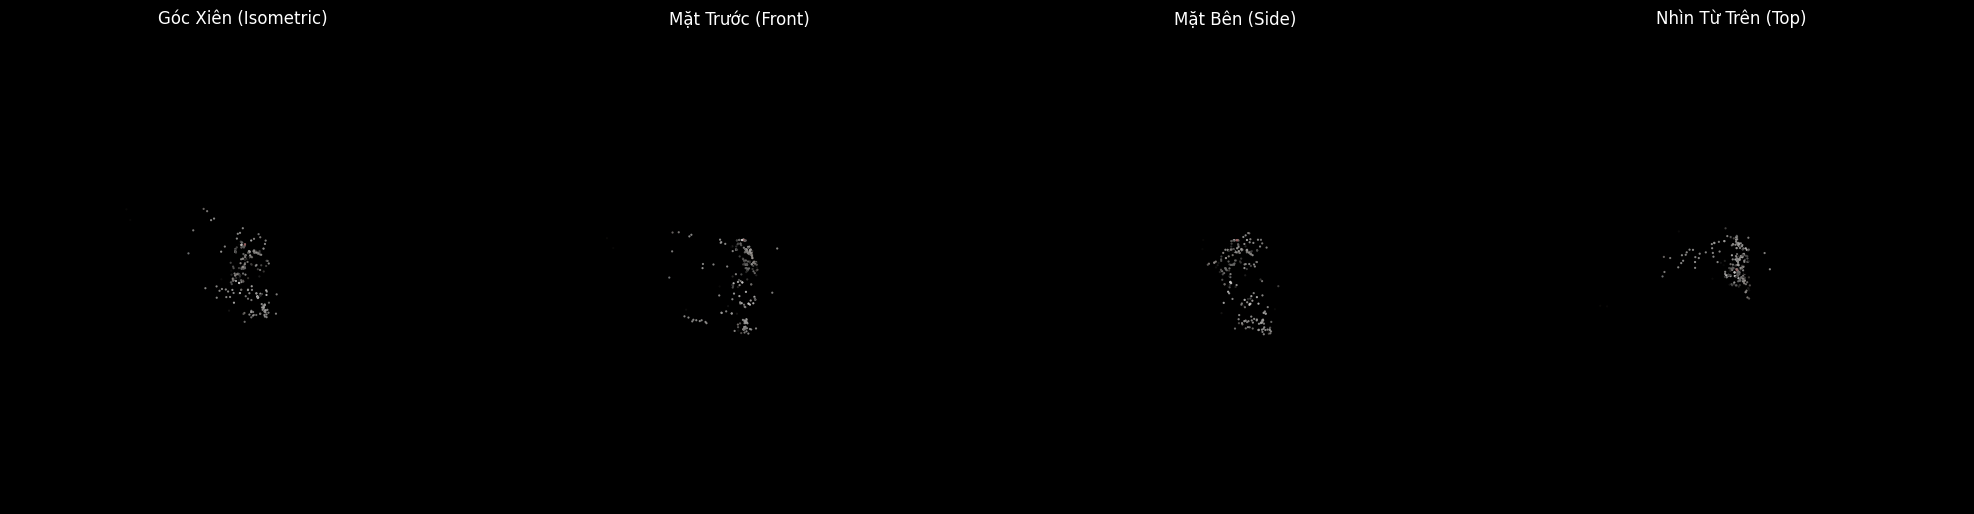

✅ Đã lưu ảnh đa góc nhìn (241 points) tại: /content/pointcloud_renders_alpha/02958343-9f703e578b4b36295b74572d48ff6382-10_mvsinit_alpha_views.png


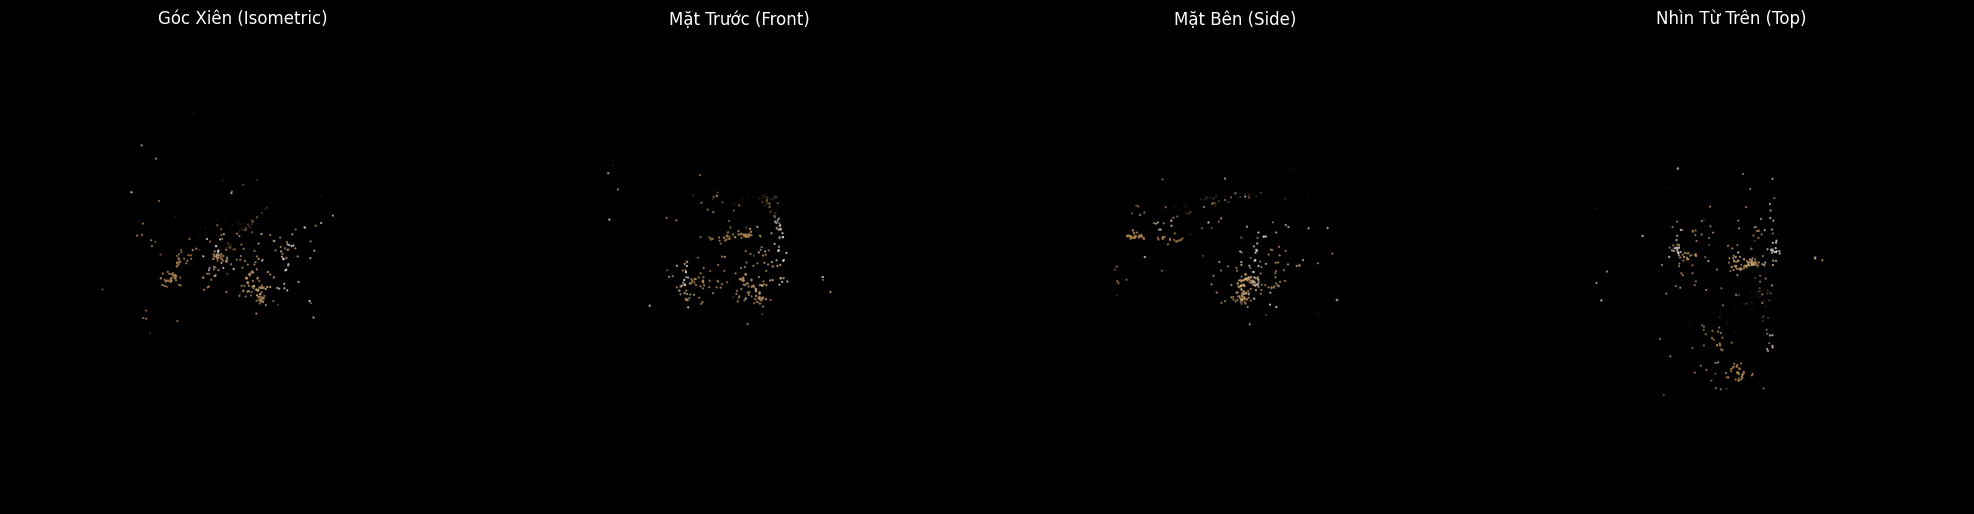

✅ Đã lưu ảnh đa góc nhìn (381 points) tại: /content/pointcloud_renders_alpha/03001627-1c199ef7e43188887215a1e3ffbff428-10_mvsinit_alpha_views.png

📁 Toàn bộ ảnh đã được lưu tại thư mục: /content/pointcloud_renders_alpha


In [ ]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

colmap_root = "/content/data/ood-nvs/test-set/shapenetOOD/colmap"
output_dir = "/content/pointcloud_renders_alpha"
os.makedirs(output_dir, exist_ok=True)

# 1. Tìm các scene alpha
scenes = sorted([
    os.path.basename(p) for p in glob.glob(os.path.join(colmap_root, "*_mvsinit_alpha"))
    if os.path.isdir(p) and "_mvsinit_mvsinit" not in p
])

def load_colmap_points3d(filepath):
    xyz, rgb = [], []
    with open(filepath, "r") as f:
        for line in f:
            if line.startswith("#") or not line.strip():
                continue
            parts = line.strip().split()
            # points3D.txt format: POINT3D_ID, X, Y, Z, R, G, B, ERROR, TRACK[]...
            xyz.append([float(parts[1]), float(parts[2]), float(parts[3])])
            rgb.append([int(parts[4]) / 255.0, int(parts[5]) / 255.0, int(parts[6]) / 255.0])
    return np.array(xyz), np.array(rgb)

# 4 góc nhìn chuẩn: (elev, azim)
camera_views = [
    {"name": "Góc Xiên (Isometric)", "elev": 30, "azim": 45},
    {"name": "Mặt Trước (Front)",     "elev": 0,  "azim": 0},
    {"name": "Mặt Bên (Side)",        "elev": 0,  "azim": 90},
    {"name": "Nhìn Từ Trên (Top)",    "elev": 90, "azim": 0}
]

print(f"Đang render point cloud 3D cho {len(scenes)} scenes...")

for sc in scenes:
    pts_file = os.path.join(colmap_root, sc, "sparse", "0", "points3D.txt")
    if not os.path.exists(pts_file):
        print(f"Không tìm thấy points3D.txt cho {sc}")
        continue

    xyz, rgb = load_colmap_points3d(pts_file)
    if len(xyz) == 0:
        print(f"Scene rỗng: {sc}")
        continue

    # Canh giữa tọa độ về gốc (0, 0, 0) để xoay camera không bị lệch khung hình
    center = np.median(xyz, axis=0)
    xyz_centered = xyz - center
    max_range = np.max(np.abs(xyz_centered)) * 1.1

    # Tạo canvas 1 hàng x 4 cột tương ứng 4 góc chụp
    fig = plt.figure(figsize=(20, 5), facecolor='black')

    for i, view in enumerate(camera_views):
        ax = fig.add_subplot(1, 4, i + 1, projection='3d', facecolor='black')
        ax.scatter(
            xyz_centered[:, 0],
            xyz_centered[:, 1],
            xyz_centered[:, 2],
            c=rgb,
            s=2.5, # kích thước hạt điểm
            alpha=0.85,
            edgecolors='none'
        )

        ax.view_init(elev=view["elev"], azim=view["azim"])
        ax.set_xlim([-max_range, max_range])
        ax.set_ylim([-max_range, max_range])
        ax.set_zlim([-max_range, max_range])

        # Ẩn trục tọa độ cho ảnh sạch sẽ như ảnh render thật
        ax.axis('off')
        ax.set_title(view["name"], color='white', fontsize=12, pad=10)

    save_path = os.path.join(output_dir, f"{sc}_views.png")
    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches='tight', facecolor='black')
    plt.show()
    plt.close()

    print(f"Đã lưu ảnh đa góc nhìn ({len(xyz)} points) tại: {save_path}")

print(f"\nToàn bộ ảnh đã được lưu tại thư mục: {output_dir}")

## Step 7 - Spltfacto optim and splatformer refinement

In [ ]:
!/usr/local/miniconda/envs/splatformer/bin/pip install -q nerfstudio==1.0.3
!apt-get update -qq && apt-get install -y -qq gcc-11 g++-11
!/usr/local/miniconda/envs/splatformer/bin/pip install -q gsplat==0.1.11

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
googleapis-common-protos 1.75.4 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
opentelemetry-proto 1.45.0 requires protobuf<8.0,>=5.0, but you have protobuf 3.20.3 which is incompatible.


In [ ]:
import subprocess, os, glob, shutil

print("=== Train splatfacto cho biến thể ALPHA ===")
CONDA_PREFIX = "/usr/local/miniconda/envs/splatformer"
NS_TRAIN_BIN = f"{CONDA_PREFIX}/bin/ns-train"

MVSINIT_ALPHA_NERFSTUDIO_ROOT = "/content/nerfstudio_out_mvsinit_alpha"
os.makedirs(MVSINIT_ALPHA_NERFSTUDIO_ROOT, exist_ok=True)

env = os.environ.copy()
env["CUDA_HOME"] = "/usr/local/cuda-11.8"
env["PATH"] = f"/usr/local/cuda-11.8/bin:{CONDA_PREFIX}/bin:" + env.get("PATH", "")
env["CC"] = "/usr/bin/gcc-11"
env["CXX"] = "/usr/bin/g++-11"
env["CUDAHOSTCXX"] = "/usr/bin/g++-11"
env["TORCH_CUDA_ARCH_LIST"] = "7.5"
env["TORCHDYNAMO_DISABLE"] = "1"


colmap_root = "/content/data/ood-nvs/test-set/shapenetOOD/colmap"

scenes_to_train = sorted([
    os.path.join(colmap_root, s + "_mvsinit_alpha") for s in scene_names_list
    if os.path.isdir(os.path.join(colmap_root, s + "_mvsinit_alpha"))
])

print(f"-> Sẽ train {len(scenes_to_train)} scene: {[os.path.basename(s) for s in scenes_to_train]}")

MAX_STEPS = 2000
mvsinit_alpha_ckpt_paths = {}

for idx, scene_dir in enumerate(scenes_to_train, 1):
    scene_name = os.path.basename(scene_dir)
    print(f"\n🚀 [{idx}/{len(scenes_to_train)}] Đang train {scene_name} ({MAX_STEPS} steps)...")

    nerfstudio_data_path = scene_dir
    nerfstudio_colmap_subdir = os.path.join(nerfstudio_data_path, "colmap")
    sparse_link_path = os.path.join(nerfstudio_colmap_subdir, "sparse")
    images_link_path = os.path.join(nerfstudio_colmap_subdir, "images")
    src_sparse_path = os.path.join(scene_dir, "sparse")
    src_images_path = os.path.join(scene_dir, "images")

    needs_setup = not os.path.exists(nerfstudio_colmap_subdir) or \
                  not os.path.exists(sparse_link_path) or not os.path.exists(images_link_path)
    if needs_setup:
        if os.path.exists(nerfstudio_colmap_subdir):
            if os.path.islink(nerfstudio_colmap_subdir):
                os.remove(nerfstudio_colmap_subdir)
            else:
                shutil.rmtree(nerfstudio_colmap_subdir)
        os.makedirs(nerfstudio_colmap_subdir, exist_ok=True)
        os.symlink(os.path.relpath(src_sparse_path, nerfstudio_colmap_subdir), sparse_link_path)
        os.symlink(os.path.relpath(src_images_path, nerfstudio_colmap_subdir), images_link_path)
        print(f"   Đã symlink sparse/images vào {nerfstudio_colmap_subdir}")
    else:
        print(f"-> [{scene_name}] Cấu trúc colmap/ đã đúng, bỏ qua.")

    cmd = [
    NS_TRAIN_BIN, "splatfacto",
    "--output-dir", MVSINIT_ALPHA_NERFSTUDIO_ROOT,
    "--experiment-name", scene_name,
    "--max-num-iterations", str(MAX_STEPS),
    "--vis", "tensorboard",
    "colmap",
    "--data", nerfstudio_data_path,
    # --- CÁC CỜ BẮT BUỘC ĐỂ GIỮ NGUYÊN TỈ LỆ VÀ TỌA ĐỘ GỐC ---
    "--auto-scale-poses", "False",
    "--center-method", "none",
    "--orientation-method", "none",
    "--scale-factor", "1.0",
    ]

    res = subprocess.run(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    print(res.stdout[-2000:])
    if res.returncode != 0:
        raise RuntimeError(f" Train {scene_name} thất bại (exit {res.returncode}).")

    ckpts = glob.glob(os.path.join(MVSINIT_ALPHA_NERFSTUDIO_ROOT, scene_name, "splatfacto", "**", "*.ckpt"), recursive=True)
    if ckpts:
        mvsinit_alpha_ckpt_paths[scene_name] = ckpts[0]
        print(f"Xong {scene_name} -> {ckpts[0]}")

print(f"\nHoàn thành huấn luyện cho {len(mvsinit_alpha_ckpt_paths)} scene biến thể ALPHA!")

=== Train splatfacto cho biến thể ALPHA ===
-> Sẽ train 10 scene: ['02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha', '02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10_mvsinit_alpha', '02958343-1f6ce6dd6720436642534f02c8e8b5ac-10_mvsinit_alpha', '02958343-9f703e578b4b36295b74572d48ff6382-10_mvsinit_alpha', '03001627-1c199ef7e43188887215a1e3ffbff428-10_mvsinit_alpha', '03001627-20c6158bbeb2735ed1dcc55e36186e4e-10_mvsinit_alpha', '03001627-bbab666132885a14ea96899baeb81e22-10_mvsinit_alpha', '03046257-108b7ee0ca90a60cdb98a62365dd8bc1-10_mvsinit_alpha', '03046257-b602321e87ba6ffedce1f8ab000da922-10_mvsinit_alpha', '03928116-71bdb3a149c93be6834096795cc3cf10-10_mvsinit_alpha']

🚀 [1/10] Đang train 02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha (2000 steps)...
   Đã symlink sparse/images vào /content/data/ood-nvs/test-set/shapenetOOD/colmap/02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha/colmap
                    
1910 (95.50%)       14.066 ms            1 s, 26

🚀 Đang render toàn bộ các scene trong conda env...
images_datamanager.py:182

[15:00:27] Caching / undistorting eval images                                             full_images_datamanager.py:196

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/content/nerfstudio_out_mvsinit_alpha/03001627-bbab666132885a14ea96899baeb81e22-10_mvsinit_alpha/splatfacto/2026-10-06_1
44909/nerfstudio_models/step-000001999.ckpt
✅ Đã render xong: 03001627-bbab666132885a14ea96899baeb81e22-10_mvsinit_alpha
[15:00:28] Using image downscale factor of 1                                                    colmap_dataparser.py:500
           Caching / undistorting train images                                            full_images_datamanager.py:182

           Caching / undistorting eval images                                             full_images_datamanager.py:196

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/content/nerfstudio_out_mvsinit_alpha/03046257-10

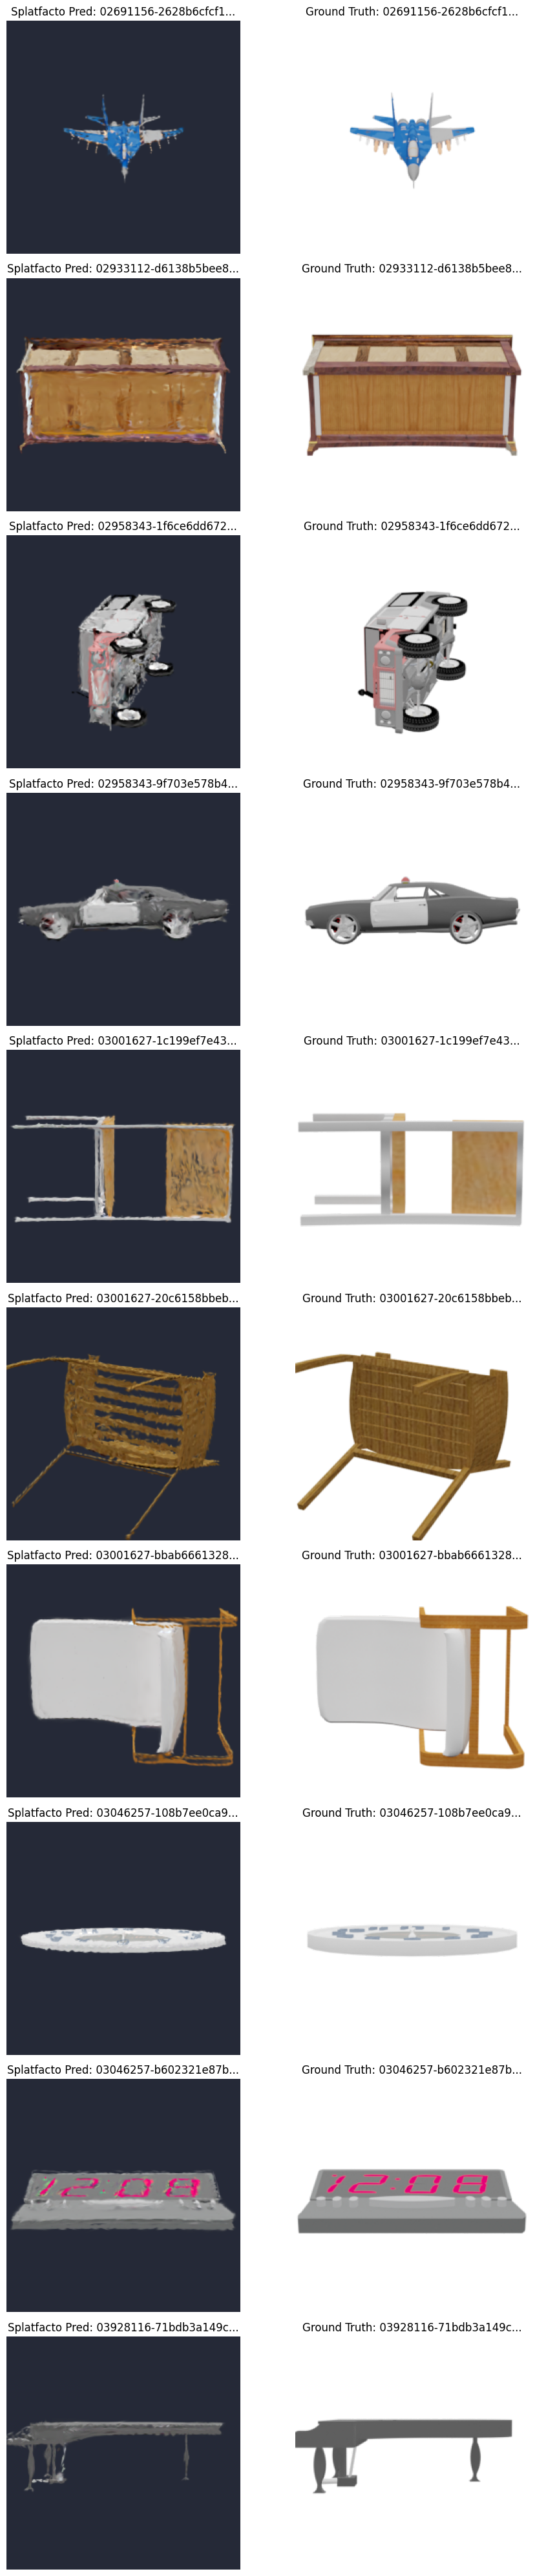

In [ ]:
import os, glob, subprocess
from PIL import Image
import matplotlib.pyplot as plt

CONDA_PYTHON = "/usr/local/miniconda/envs/splatformer/bin/python"

# 1. Tạo script render toàn bộ 5 scene alpha
render_script = """
import os, glob, torch
from pathlib import Path
import matplotlib.pyplot as plt
from nerfstudio.utils.eval_utils import eval_setup

nerfstudio_root = "/content/nerfstudio_out_mvsinit_alpha"
output_dir = "/content/alpha_preview_all"
os.makedirs(output_dir, exist_ok=True)

# Lấy tất cả thư mục scene alpha
scene_dirs = sorted(glob.glob(os.path.join(nerfstudio_root, "*_mvsinit_alpha")))

for sdir in scene_dirs:
    scene_name = os.path.basename(sdir)
    config_files = glob.glob(os.path.join(sdir, "splatfacto", "**", "config.yml"), recursive=True)
    if not config_files:
        print(f"⚠️ Không tìm thấy config cho {scene_name}")
        continue

    config_path = Path(config_files[0])
    try:
        _, pipeline, _, _ = eval_setup(config_path, test_mode="test")
        camera, batch = pipeline.datamanager.next_eval(0)
        with torch.no_grad():
            outputs = pipeline.model.get_outputs_for_camera(camera)

        pred_rgb = outputs["rgb"].detach().cpu().numpy()
        gt_rgb = batch["image"].detach().cpu().numpy()

        plt.imsave(f"{output_dir}/{scene_name}_pred.png", pred_rgb)
        plt.imsave(f"{output_dir}/{scene_name}_gt.png", gt_rgb)
        print(f"✅ Đã render xong: {scene_name}")
    except Exception as e:
        print(f"❌ Lỗi khi render {scene_name}: {e}")
"""

with open("/content/run_render_all.py", "w") as f:
    f.write(render_script)

env = os.environ.copy()
env["CUDA_HOME"] = "/usr/local/cuda-11.8"
env["PATH"] = f"/usr/local/cuda-11.8/bin:/usr/local/miniconda/envs/splatformer/bin:" + env.get("PATH", "")
env["CC"] = "/usr/bin/gcc-11"
env["CXX"] = "/usr/bin/g++-11"
env["CUDAHOSTCXX"] = "/usr/bin/g++-11"
env["TORCH_CUDA_ARCH_LIST"] = "7.5"
env["TORCHDYNAMO_DISABLE"] = "1"

print("🚀 Đang render toàn bộ các scene trong conda env...")
res = subprocess.run([CONDA_PYTHON, "/content/run_render_all.py"], env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
print(res.stdout[-2500:])

# 2. Hiển thị đối chiếu 5 scene (5 hàng x 2 cột)
preview_dir = "/content/alpha_preview_all"
pred_files = sorted(glob.glob(os.path.join(preview_dir, "*_pred.png")))

if pred_files:
    n = len(pred_files)
    fig, axes = plt.subplots(n, 2, figsize=(10, 4 * n))
    if n == 1:
        axes = [axes]

    for i, p_file in enumerate(pred_files):
        sc_name = os.path.basename(p_file).replace("_pred.png", "")
        gt_file = os.path.join(preview_dir, f"{sc_name}_gt.png")

        axes[i][0].imshow(Image.open(p_file))
        axes[i][0].set_title(f"Splatfacto Pred: {sc_name[:20]}...")
        axes[i][0].axis("off")

        if os.path.exists(gt_file):
            axes[i][1].imshow(Image.open(gt_file))
            axes[i][1].set_title(f"Ground Truth: {sc_name[:20]}...")
            axes[i][1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print(" Chưa render được ảnh nào.")

## Step 8  - Quantitative 2D evalutation (PSNR/SSIM/LPIPS)

In [ ]:
import os, subprocess

PIP_BIN = "/usr/local/miniconda/envs/splatformer/bin/pip"
subprocess.run(f"{PIP_BIN} install -q pandas lpips scikit-image", shell=True, check=True)

eval_script = """
import os, glob, torch
import numpy as np
import pandas as pd
from PIL import Image
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
import lpips

print("=== BƯỚС 6-ood: Tính toán trực tiếp Metrics từ ảnh Render (Biến thể ALPHA) ===")

pred_dir = "/content/SplatFormer/outputs/ood_eval_mvsinit_alpha/test/default"
loss_fn_vgg = lpips.LPIPS(net='vgg').cuda()

colmap_base_dir = "/content/data/ood-nvs/test-set/shapenetOOD/colmap"
scenes = sorted([
    os.path.basename(p) for p in glob.glob(os.path.join(colmap_base_dir, "*_mvsinit_alpha"))
    if os.path.isdir(p) and "_mvsinit_mvsinit" not in p
])

rows = []

# Quét 5 scene từ scene0 đến scene4
for i in range(len(scenes)):
    gt_path = os.path.join(pred_dir, f"scene{i}_gt.png")
    pred_path = os.path.join(pred_dir, f"scene{i}_pred.png")

    if not (os.path.exists(gt_path) and os.path.exists(pred_path)):
        print(f"Thiếu ảnh cho scene {i} tại {gt_path}")
        continue

    # Đọc ảnh chuẩn thang [0, 1]
    img_gt = np.array(Image.open(gt_path).convert("RGB")).astype(np.float32) / 255.0
    img_pred = np.array(Image.open(pred_path).convert("RGB")).astype(np.float32) / 255.0

    # Tính PSNR & SSIM
    cur_psnr = psnr_fn(img_gt, img_pred, data_range=1.0)
    cur_ssim = ssim_fn(img_gt, img_pred, channel_axis=-1, data_range=1.0)

    # Tính LPIPS
    t_gt = torch.from_numpy(img_gt).permute(2, 0, 1).unsqueeze(0).cuda() * 2.0 - 1.0
    t_pred = torch.from_numpy(img_pred).permute(2, 0, 1).unsqueeze(0).cuda() * 2.0 - 1.0
    with torch.no_grad():
        cur_lpips = loss_fn_vgg(t_gt, t_pred).item()

    rows.append({
        "Scene_ID": i,
        "Scene_Name": scenes[i] if i < len(scenes) else f"scene_{i}",
        "Variant": "MVS-init (Biến thể ALPHA)",
        "PSNR": round(float(cur_psnr), 2),
        "SSIM": round(float(cur_ssim), 4),
        "LPIPS": round(float(cur_lpips), 4)
    })

df = pd.DataFrame(rows)
print("\\n--- BẢNG KẾT QUẢ ĐÁNH GIÁ 5 SCENE (MVS-INIT ALPHA) ---")
print(df.to_string(index=False))

if not df.empty:
    print(f"\\n---  METRICS TRUNG BÌNH TOÀN BỘ BENCHMARK ({len(df)} SCENES) ---")
    print(f"  * PSNR : {df['PSNR'].mean():.2f} dB")
    print(f"  * SSIM : {df['SSIM'].mean():.4f}")
    print(f"  * LPIPS: {df['LPIPS'].mean():.4f}")

    csv_out = "/content/metrics_mvsinit_alpha.csv"
    df.to_csv(csv_out, index=False)
    print(f"\\n Đã lưu bảng metrics tại: {csv_out}")
"""

with open("/content/run_eval_alpha.py", "w") as f:
    f.write(eval_script)

CONDA_PYTHON = "/usr/local/miniconda/envs/splatformer/bin/python"
res = subprocess.run([CONDA_PYTHON, "/content/run_eval_alpha.py"], text=True, capture_output=True)
print(res.stdout)
if res.stderr and res.returncode != 0:
    print("Lỗi:\n", res.stderr)

=== BƯỚС 6-ood: Tính toán trực tiếp Metrics từ ảnh Render (Biến thể ALPHA) ===
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /usr/local/miniconda/envs/splatformer/lib/python3.10/site-packages/lpips/weights/v0.1/vgg.pth

--- 📊 BẢNG KẾT QUẢ ĐÁNH GIÁ 5 SCENE (MVS-INIT ALPHA) ---
 Scene_ID                                                 Scene_Name                   Variant  PSNR   SSIM  LPIPS
        0 02691156-2628b6cfcf1a53465569af4484881d20-10_mvsinit_alpha MVS-init (Biến thể ALPHA) 13.81 0.7710 0.2578
        1 02933112-d6138b5bee8f009ebd9c9454e3d4e73d-10_mvsinit_alpha MVS-init (Biến thể ALPHA) 13.94 0.5474 0.3821
        2 02958343-1f6ce6dd6720436642534f02c8e8b5ac-10_mvsinit_alpha MVS-init (Biến thể ALPHA) 12.18 0.6600 0.2958
        3 02958343-9f703e578b4b36295b74572d48ff6382-10_mvsinit_alpha MVS-init (Biến thể ALPHA) 13.63 0.7313 0.2769
        4 03001627-1c199ef7e43188887215a1e3ffbff428-10_mvsinit_alpha MVS-init (Biến thể ALPHA) 11.53 0.